In [ ]:
import math
import re
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, roc_curve, roc_auc_score

import pickle

#Loading the dataset
!wget -q -O cardiovascular_dataset.zip \
"https://www.kaggle.com/api/v1/datasets/download/sulianova/cardiovascular-disease-dataset"

import zipfile

with zipfile.ZipFile(
    "cardiovascular_dataset.zip",
    "r"
) as zip_ref:

    zip_ref.extractall("cardiovascular_data")

df = pd.read_csv(
    "cardiovascular_data/cardio_train.csv",
    sep=";"
)

list(df.columns)

['id',
 'age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'cardio']

In [ ]:
pd.concat([df.head(5), df.sample(5), df.tail(5)])

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0
15117,21616,20296,1,168,70.0,140,90,1,1,0,0,1,1
34793,49700,18135,2,170,70.0,120,80,1,1,1,1,0,0
38992,55672,20457,1,150,59.0,90,60,2,1,0,0,1,0
44935,64170,21942,2,169,80.0,140,80,2,1,1,1,1,0
65856,93995,17983,2,174,88.0,120,80,3,1,0,0,1,1


In [ ]:
df.describe(include='all').T

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


# **Preprocessing**

unique values

In [ ]:
pd.DataFrame([ df.nunique(), df.dtypes ], index=['Unique Values', 'Data Types'])

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
Unique Values,70000,8076,2,109,287,153,157,3,3,2,2,2,2
Data Types,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64


In [ ]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

In [ ]:
TARGET = 'cardio'

INPUT_FEATURES = [
    'id', 'age', 'gender', 'height', 'weight',
    'ap_hi', 'ap_lo', 'cholesterol', 'gluc',
    'smoke', 'alco', 'active'
]

# Check the dataset
pd.DataFrame(
    [df.nunique(), df.dtypes],
    index=['Unique Values', 'Data Types']
)

# Check for duplicate rows
duplicates = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicates}")

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print(f"Dataset shape after removing duplicates: {df.shape}")

# Check for missing values
pd.DataFrame(
    {
        "Count": df.isna().sum().sort_values(ascending=False),
        "percent %": 100.0 * df.isna().sum().sort_values(ascending=False) / len(df),
    }
).T

# Check categorical values for consistency
for col in ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())

# Function for removing unwanted features
def drop_unwanted_features(df, feature_to_drop):
    print(f"\nDropping feature: {feature_to_drop}")

    if feature_to_drop in df.columns:
        df = df.drop(columns=[feature_to_drop])

    if feature_to_drop in INPUT_FEATURES:
        INPUT_FEATURES.remove(feature_to_drop)

    return df

# Remove ID because it is an identifier, not a predictive feature
df = drop_unwanted_features(df, 'id')

Number of duplicate rows: 0
Dataset shape after removing duplicates: (70000, 13)

gender
gender
1    45530
2    24470
Name: count, dtype: int64

cholesterol
cholesterol
1    52385
2     9549
3     8066
Name: count, dtype: int64

gluc
gluc
1    59479
2     5190
3     5331
Name: count, dtype: int64

smoke
smoke
0    63831
1     6169
Name: count, dtype: int64

alco
alco
0    66236
1     3764
Name: count, dtype: int64

active
active
0    13739
1    56261
Name: count, dtype: int64

cardio
cardio
0    35021
1    34979
Name: count, dtype: int64

Dropping feature: id


In [ ]:
print(f"Dataset shape before removing duplicates: {df.shape}")

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print(f"Dataset shape after removing duplicates: {df.shape}")

Dataset shape before removing duplicates: (70000, 12)
Dataset shape after removing duplicates: (69976, 12)


In [ ]:
# Check blood pressure consistency

invalid_bp = df['ap_lo'] >= df['ap_hi']

print(
    f"Records where diastolic BP >= systolic BP: "
    f"{invalid_bp.sum()}"
)

# Remove invalid BP records
df = df[df['ap_lo'] < df['ap_hi']].copy()

print(f"Dataset shape after BP cleaning: {df.shape}")

Records where diastolic BP >= systolic BP: 1236
Dataset shape after BP cleaning: (68740, 12)


In [ ]:
list(df.columns)

['age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'cardio']

Outliers

In [ ]:
def find_iqr_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return (series < lower) | (series > upper)


outlier_features = ['age', 'height', 'weight', 'ap_hi', 'ap_lo']

# Detect outliers per feature and report counts
outlier_flags = pd.DataFrame({
    feature: find_iqr_outliers(df[feature])
    for feature in outlier_features
})

print("Outliers detected per feature:")
for feature in outlier_features:
    n_outliers = outlier_flags[feature].sum()
    pct_outliers = 100 * outlier_flags[feature].mean()
    print(f"  {feature}: {n_outliers} outliers ({pct_outliers:.2f}%)")

row_is_outlier = outlier_flags.any(axis=1)

print(
    f"\nRows flagged as outliers overall: "
    f"{row_is_outlier.sum()} ({100 * row_is_outlier.mean():.2f}% of dataset)"
)

# Remove outlier rows
df = df[~row_is_outlier].reset_index(drop=True)

print(f"Dataset shape after outlier removal: {df.shape}")

Outliers detected per feature:
  age: 4 outliers (0.01%)
  height: 506 outliers (0.74%)
  weight: 1746 outliers (2.54%)
  ap_hi: 1058 outliers (1.54%)
  ap_lo: 3570 outliers (5.19%)

Rows flagged as outliers overall: 6265 (9.11% of dataset)
Dataset shape after outlier removal: (62475, 12)


In [ ]:
print(df.head(10))

     age  gender  height  weight  ap_hi  ap_lo  cholesterol  gluc  smoke  \
0  18393       2     168    62.0    110     80            1     1      0   
1  20228       1     156    85.0    140     90            3     1      0   
2  18857       1     165    64.0    130     70            3     1      0   
3  17623       2     169    82.0    150    100            1     1      0   
4  21914       1     151    67.0    120     80            2     2      0   
5  22113       1     157    93.0    130     80            3     1      0   
6  22584       2     178    95.0    130     90            3     3      0   
7  17668       1     158    71.0    110     70            1     1      0   
8  22530       1     169    80.0    120     80            1     1      0   
9  18815       2     173    60.0    120     80            1     1      0   

   alco  active  cardio  
0     0       1       0  
1     0       1       1  
2     0       0       1  
3     0       1       1  
4     0       0       0  
5     0

# **EDA & Dataset Visualization**

Barcharts

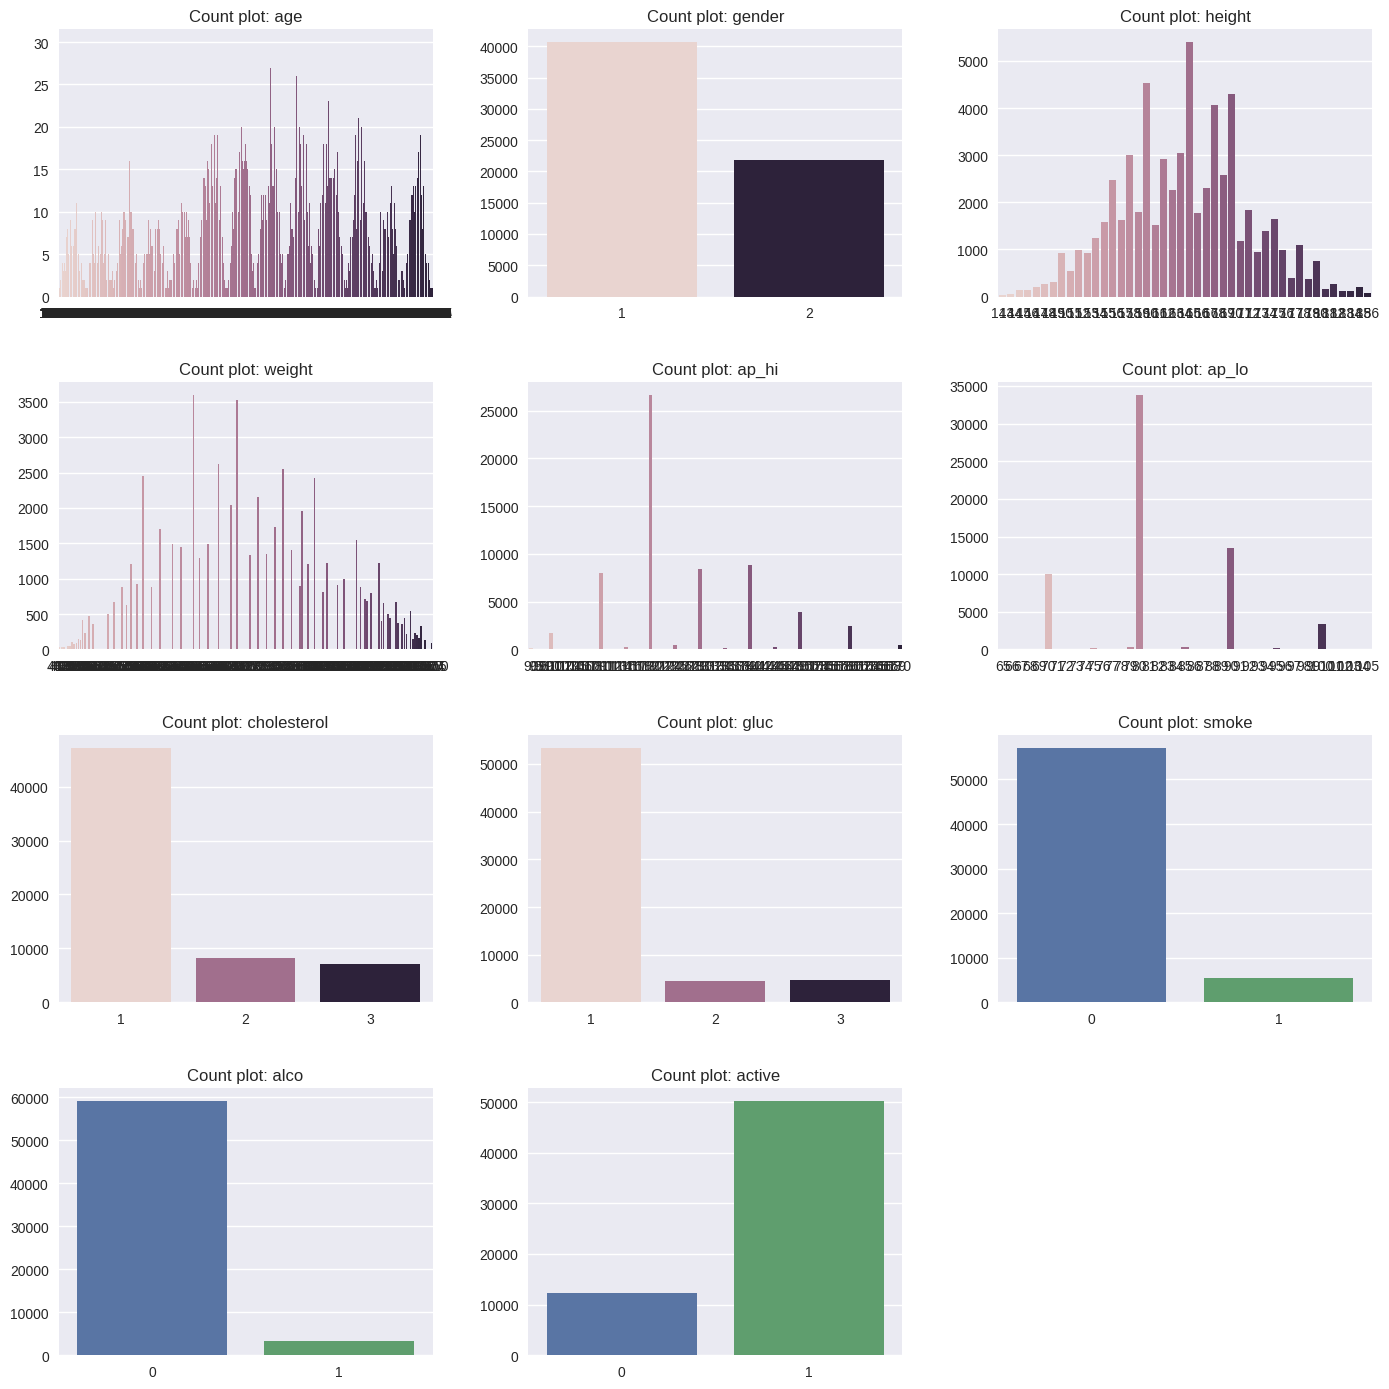

In [ ]:
plt.style.use(plt.style.available[12])

N_COLS = 3
N_ROWS = math.ceil(len(INPUT_FEATURES) / N_COLS)

plt.figure(figsize=(14, 3.5 * N_ROWS))

for i, cat_feature in enumerate(INPUT_FEATURES):
    plt.subplot(N_ROWS, N_COLS, i+1)
    plt.title(f"Count plot: {cat_feature}")
    sns.countplot(data=df, x=cat_feature, hue=cat_feature, legend=False)
    plt.ylabel("")
    plt.xlabel('')

plt.tight_layout(h_pad=3.0, w_pad=2.0)

plt.show()

Histograms

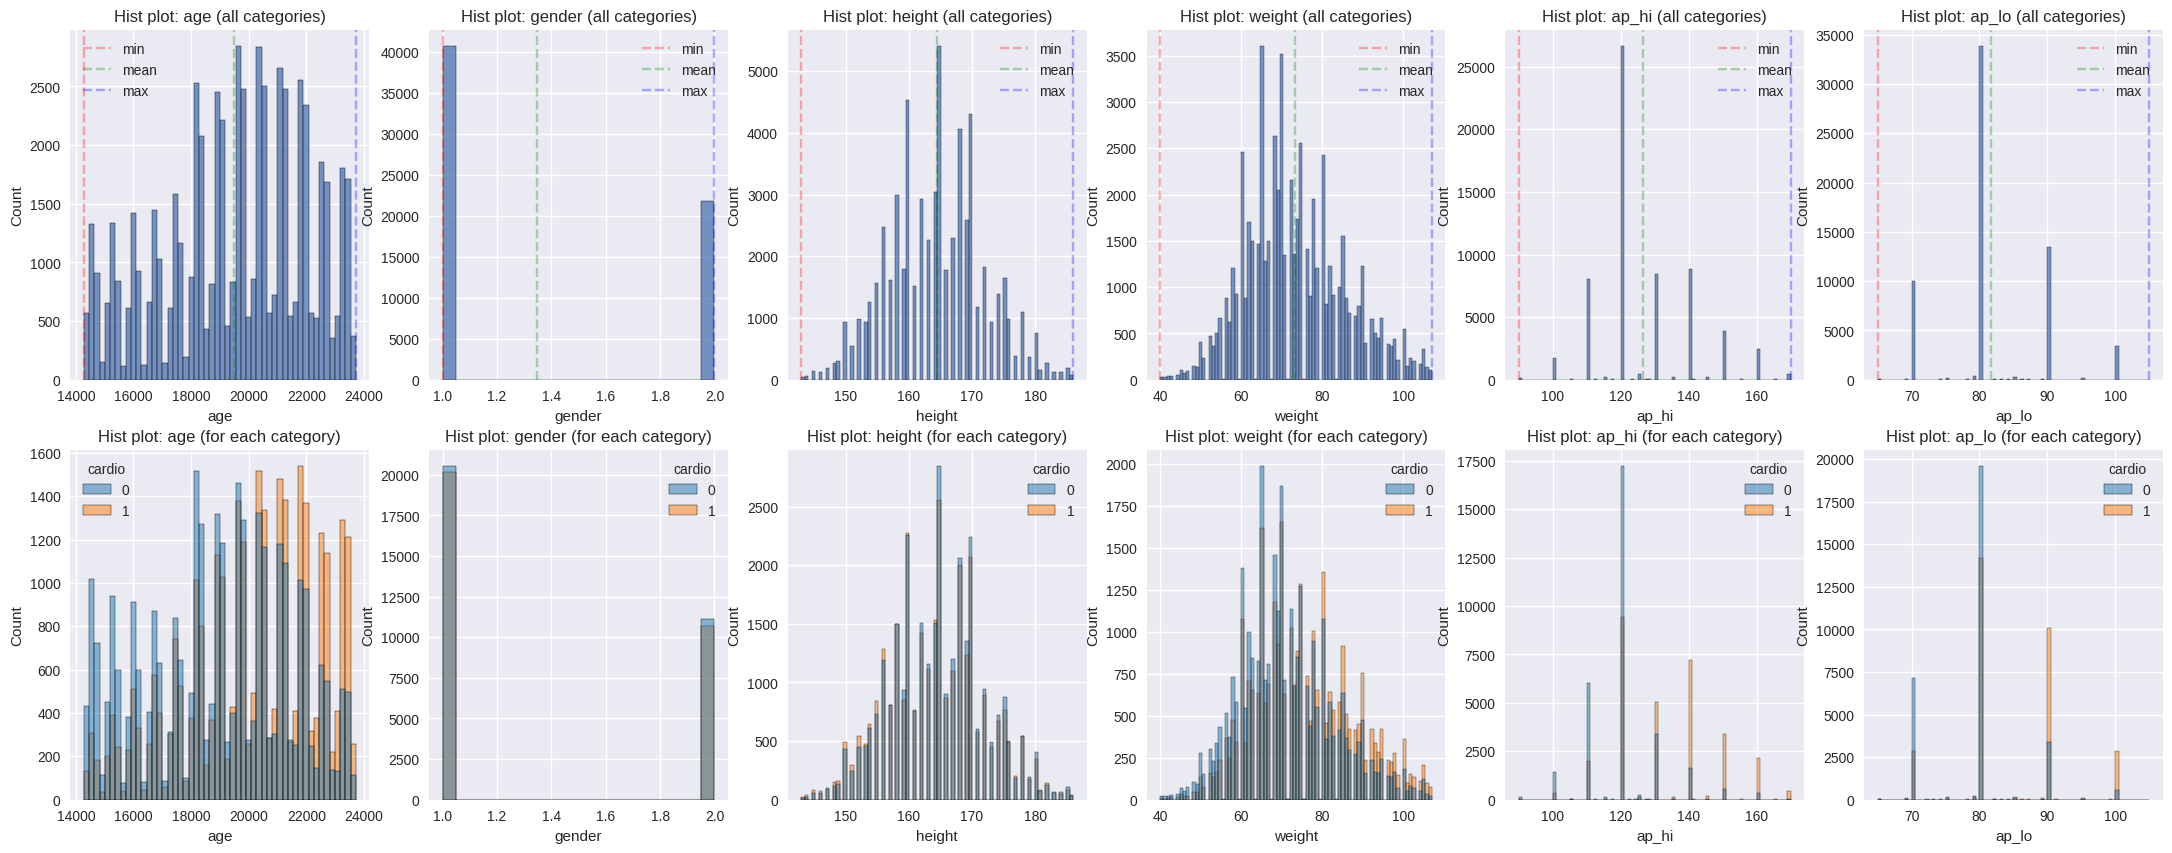

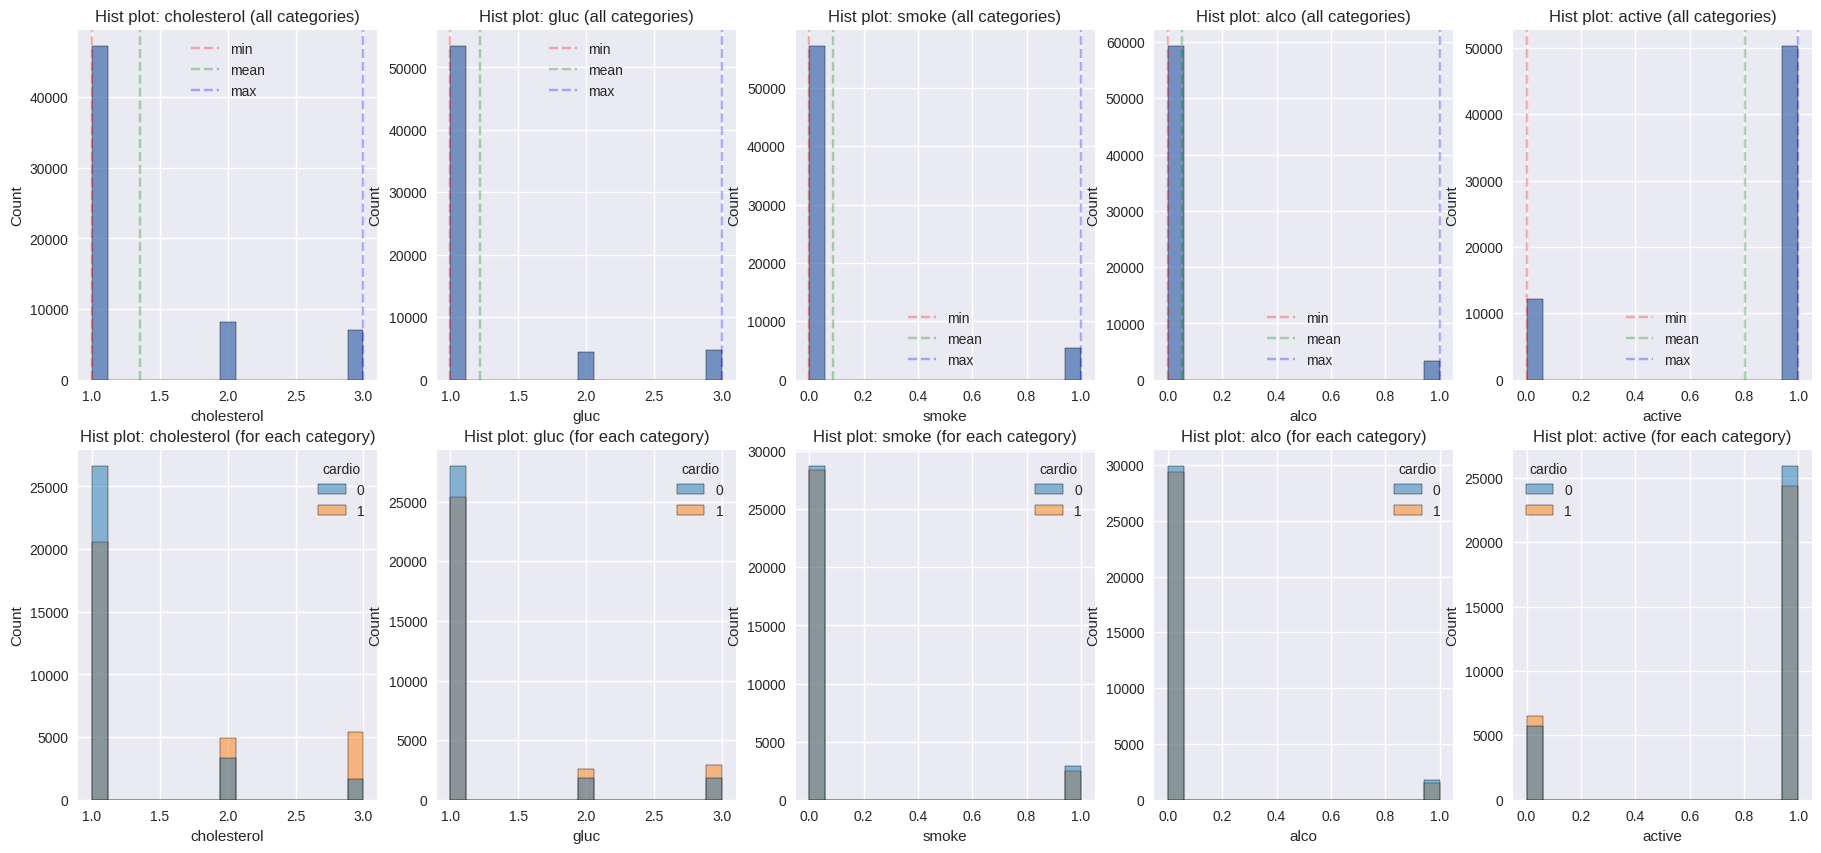

In [ ]:
ROW_WIDTH = 6
temp = 0

numeric_features = [
    feature for feature in INPUT_FEATURES
    if df[feature].dtype in ['int64', 'float64', 'int32', 'float32']
    and feature not in ['bmi_category', 'hypertension_stage']
]

for num_feature in numeric_features:
    if temp == 0:
        plt.figure(figsize=(27,10))

    plt.subplot(2,ROW_WIDTH, temp + 1)
    plt.title(f"Hist plot: {num_feature} (all categories)")
    sns.histplot(df, x=num_feature, )

    plt.axvline(x= df[num_feature].min() , label="min", color='r', linestyle='--', alpha = 0.3)
    plt.axvline(x= df[num_feature].mean() , label="mean", color='g', linestyle='--', alpha = 0.3)
    plt.axvline(x= df[num_feature].max() , label="max", color='b', linestyle='--', alpha = 0.3)

    plt.legend()


    plt.subplot(2,ROW_WIDTH, (temp + 1) + ROW_WIDTH)
    plt.title(f"Hist plot: {num_feature} (for each category)")
    sns.histplot(df, x=num_feature, hue=TARGET, palette='tab10')

    if temp == ROW_WIDTH - 1:
        plt.show()

    temp = (temp + 1) % ROW_WIDTH

if temp != ROW_WIDTH - 1:
    plt.show()

Count of CVD vs No CVD

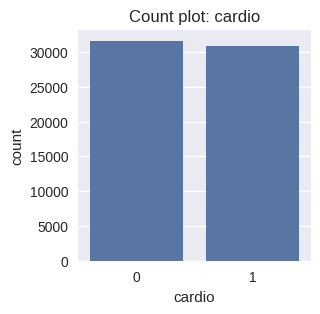

In [ ]:
plt.figure(figsize=(3,3))
plt.title(f"Count plot: {TARGET}")
sns.countplot(df, x=TARGET)
plt.show()

Kernel Density Estimate (KDE) plots

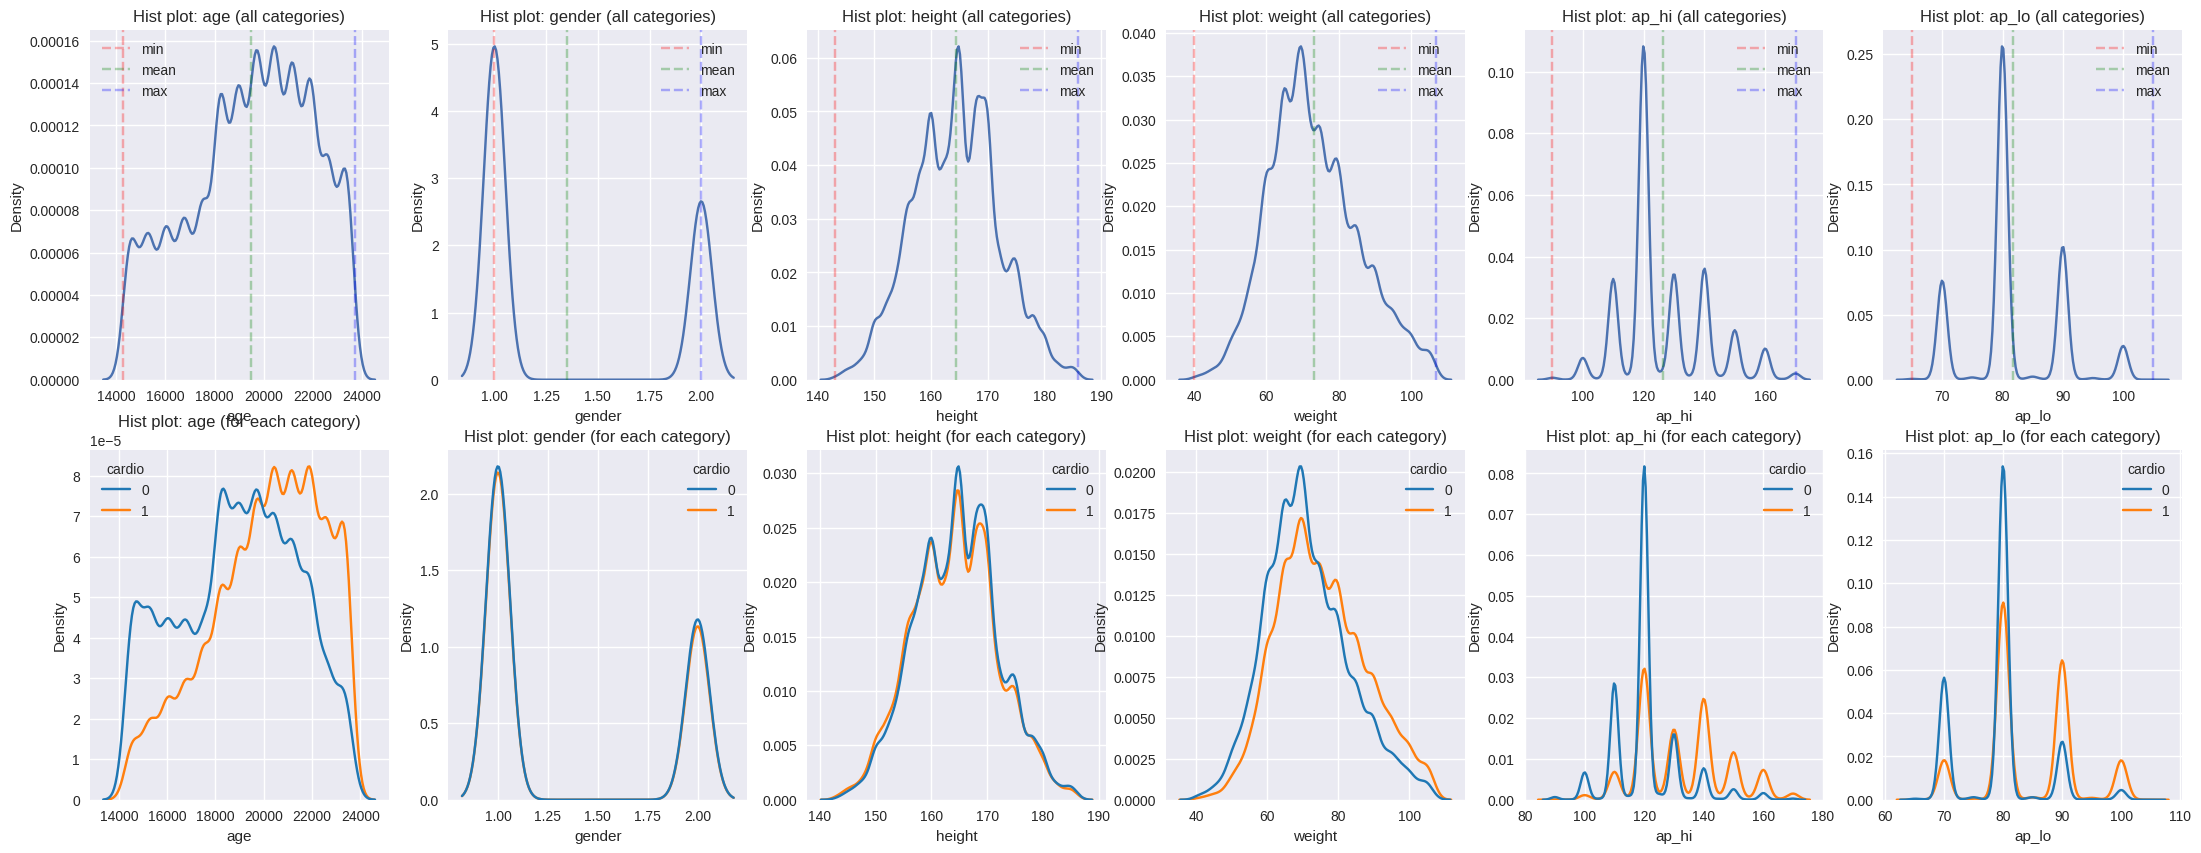

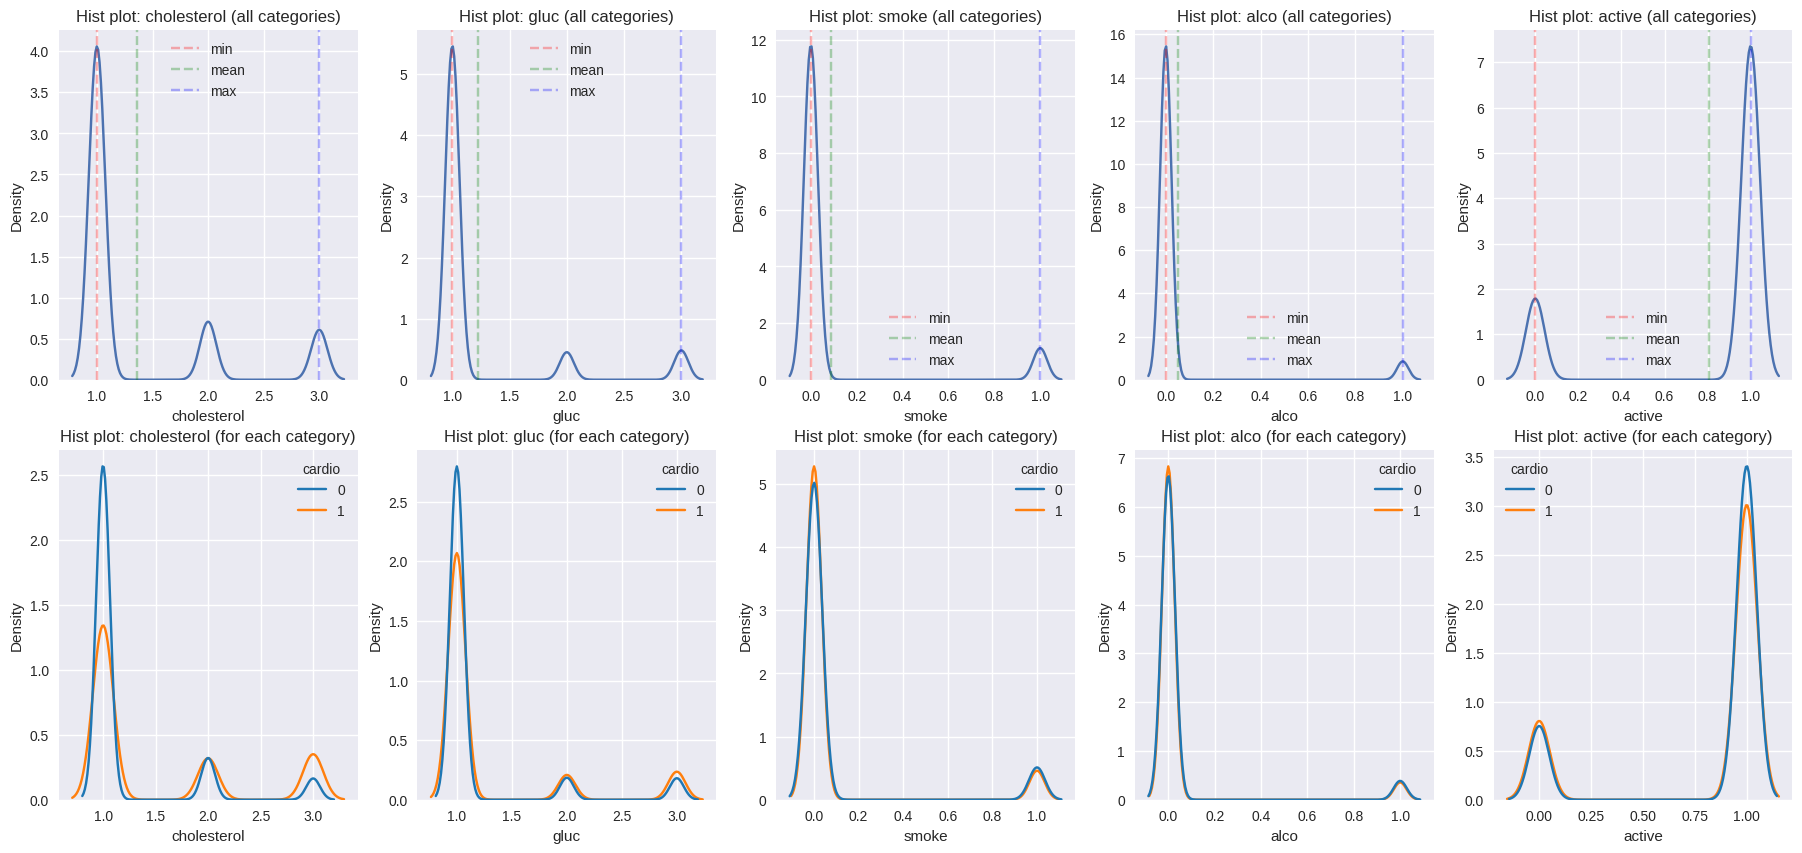

In [ ]:
ROW_WIDTH = 6
temp = 0

numeric_features = [
    feature for feature in INPUT_FEATURES
    if df[feature].dtype in ['int64', 'float64', 'int32', 'float32']
    and feature not in ['bmi_category', 'hypertension_stage']
]

for num_feature in numeric_features:
    if temp == 0:
        plt.figure(figsize=(27,10))

    plt.subplot(2,ROW_WIDTH, temp + 1)
    plt.title(f"Hist plot: {num_feature} (all categories)")
    sns.kdeplot(df, x=num_feature, )

    plt.axvline(x= df[num_feature].min() , label="min", color='r', linestyle='--', alpha = 0.3)
    plt.axvline(x= df[num_feature].mean() , label="mean", color='g', linestyle='--', alpha = 0.3)
    plt.axvline(x= df[num_feature].max() , label="max", color='b', linestyle='--', alpha = 0.3)

    plt.legend()


    plt.subplot(2,ROW_WIDTH, (temp + 1) + ROW_WIDTH)
    plt.title(f"Hist plot: {num_feature} (for each category)")
    sns.kdeplot(df, x=num_feature, hue=TARGET, palette='tab10')

    if temp == ROW_WIDTH - 1:
        plt.show()

    temp = (temp + 1) % ROW_WIDTH

if temp != ROW_WIDTH - 1:
    plt.show()

Box-plots

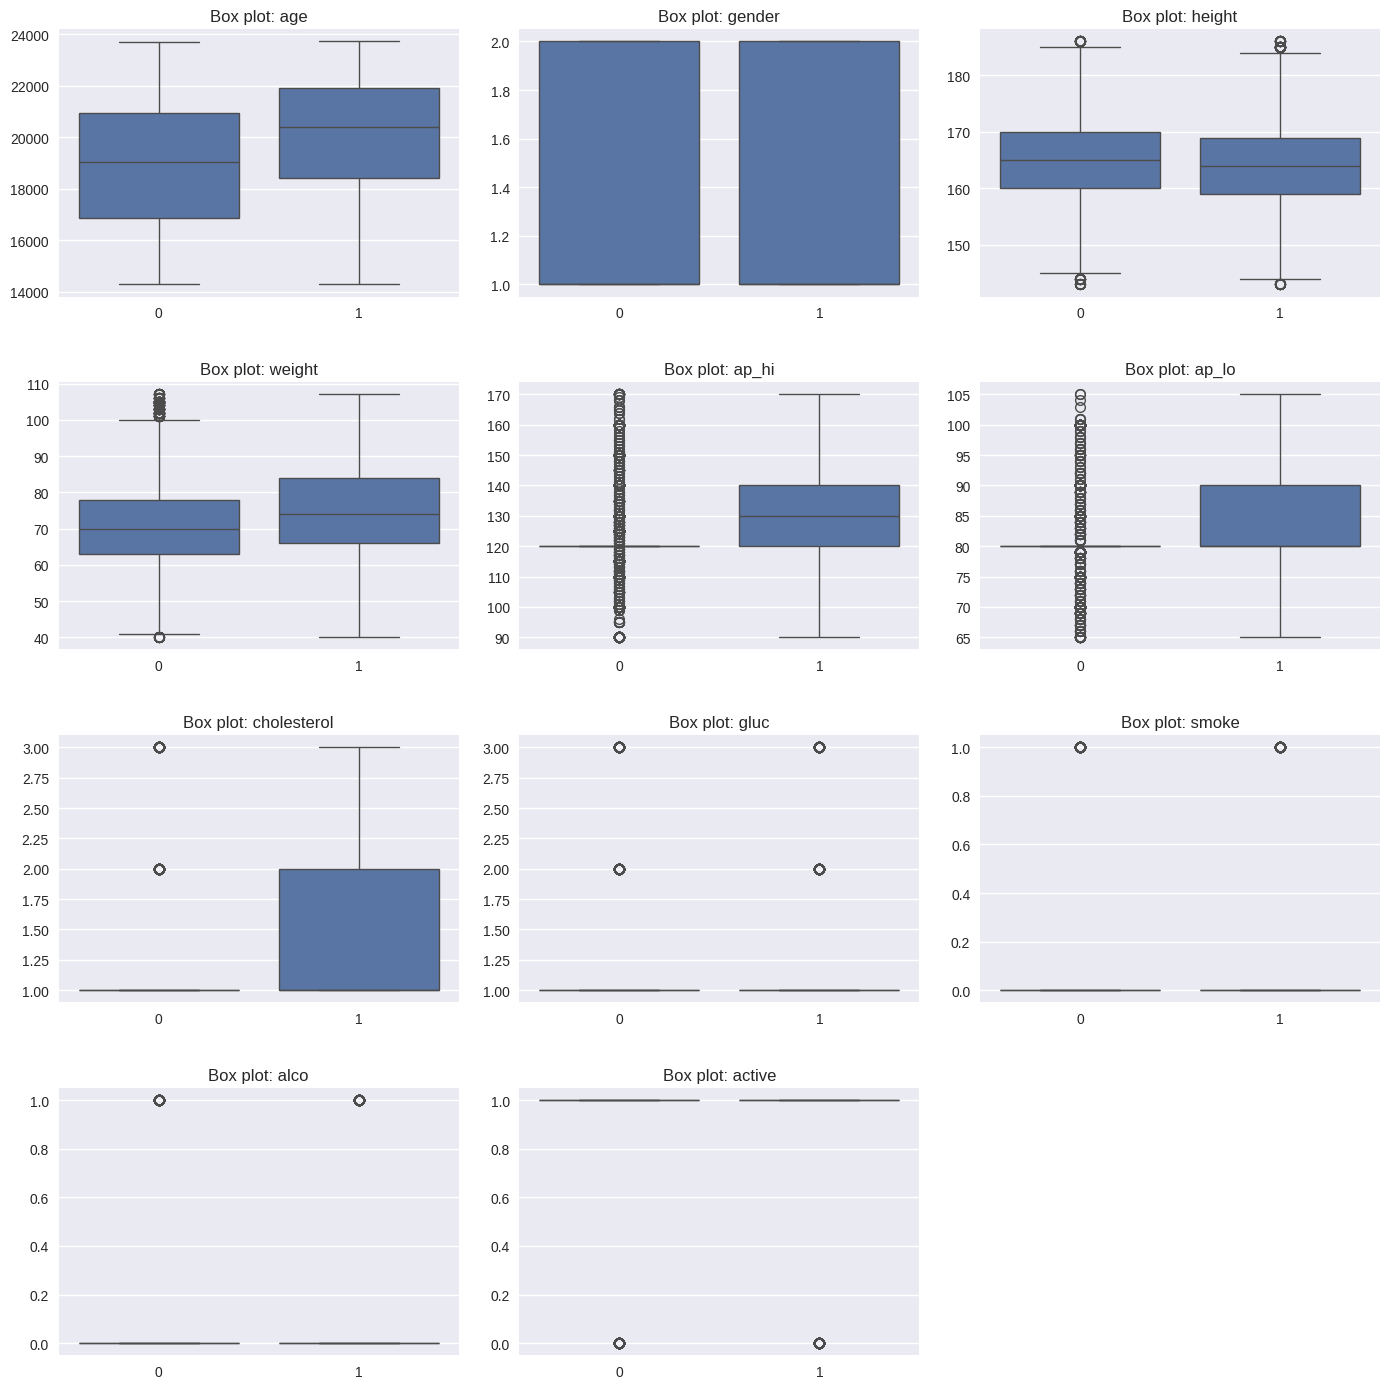

In [ ]:
N_COLS = 3
N_ROWS = math.ceil(len(INPUT_FEATURES) / N_COLS)

plt.figure(figsize=(14, 3.5 * N_ROWS))

for i, feature in enumerate(INPUT_FEATURES):
    plt.subplot(N_ROWS, N_COLS, i+1)
    plt.title(f"Box plot: {feature}")
    sns.boxplot(df, x=TARGET, y=feature)
    plt.ylabel("")
    plt.xlabel('')

plt.tight_layout(h_pad=3.0, w_pad=2.0)
plt.show()

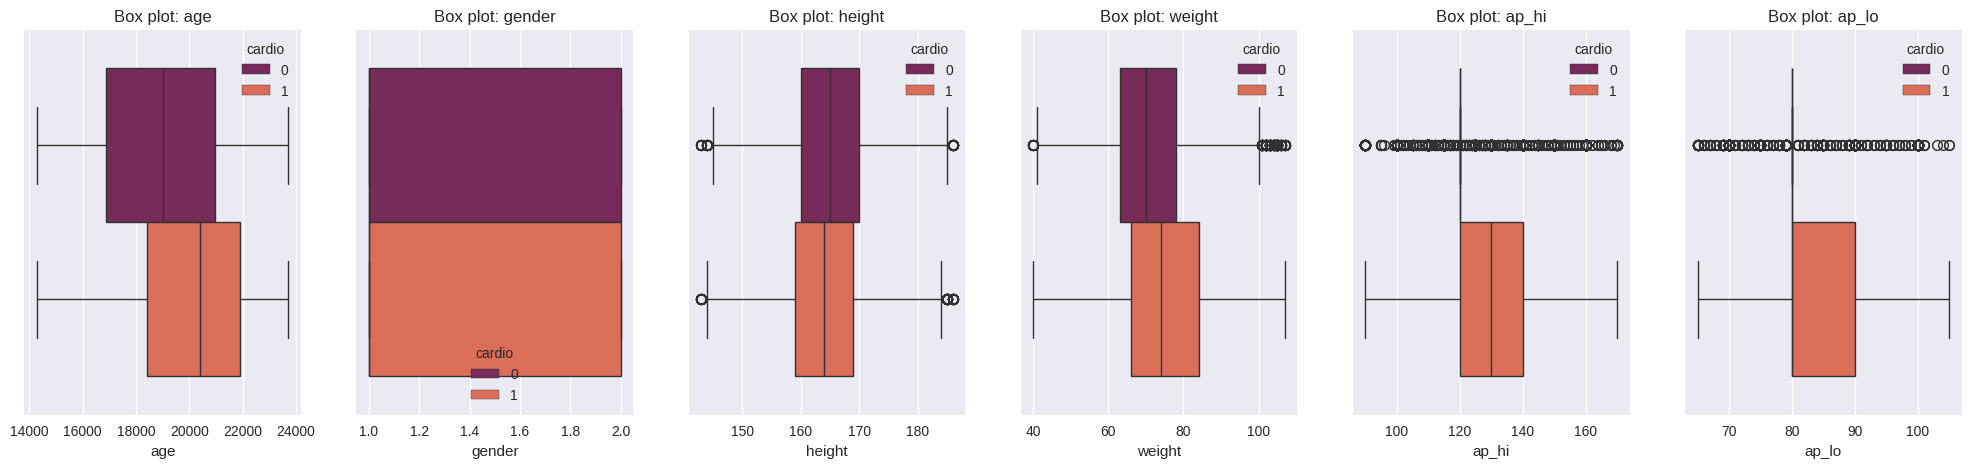

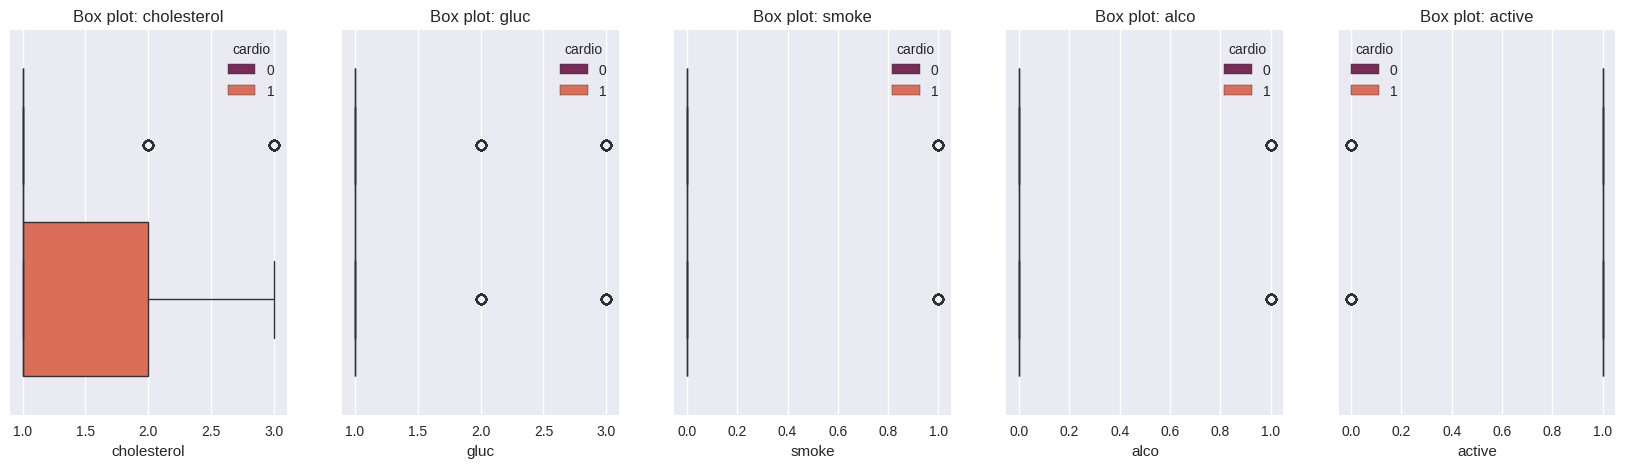

In [ ]:
def plot_box(features, hue):
    ROW_WIDTH = 6
    temp = 0

    for num_feature in features:
        if temp == 0:
            plt.figure(figsize=(25,5))

        plt.subplot(1,ROW_WIDTH, temp + 1)
        plt.title(f"Box plot: {num_feature}")
        sns.boxplot(df, x=num_feature, hue=hue, palette='rocket')

        if temp == ROW_WIDTH - 1:
            plt.show()

        temp = (temp + 1) % ROW_WIDTH

    if temp != ROW_WIDTH - 1:
        plt.show()

plot_box(INPUT_FEATURES, TARGET)

Scatter-plots

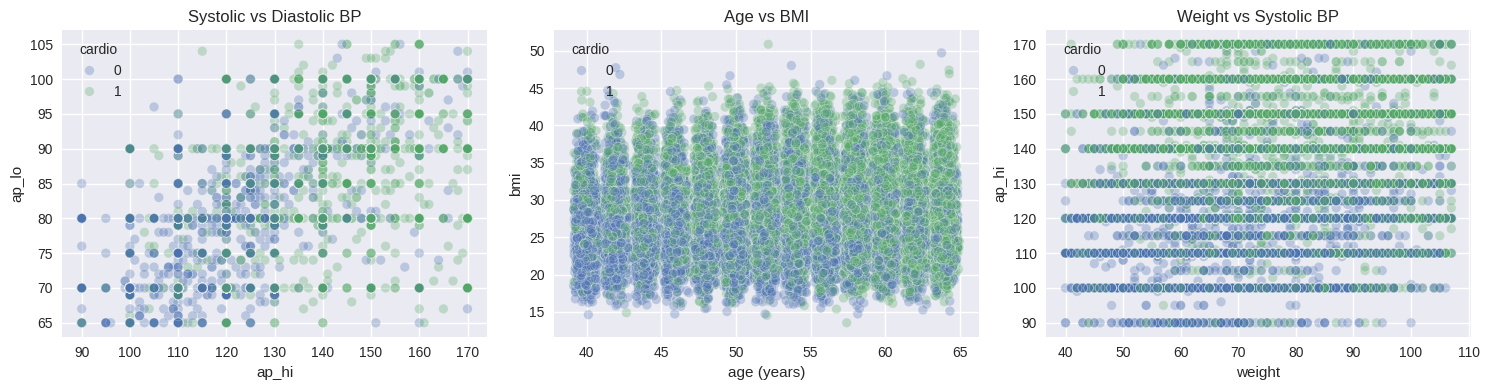

In [ ]:
#Scatter plots
bmi_tmp = df['weight'] / ((df['height'] / 100) ** 2)
age_years_tmp = df['age'] / 365

plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
sns.scatterplot(df, x='ap_hi', y='ap_lo', hue=TARGET, alpha=0.3)
plt.title("Systolic vs Diastolic BP")

plt.subplot(1,3,2)
sns.scatterplot(x=age_years_tmp, y=bmi_tmp, hue=df[TARGET], alpha=0.3)
plt.xlabel("age (years)")
plt.ylabel("bmi")
plt.title("Age vs BMI")

plt.subplot(1,3,3)
sns.scatterplot(df, x='weight', y='ap_hi', hue=TARGET, alpha=0.3)
plt.title("Weight vs Systolic BP")

plt.tight_layout()
plt.show()


Correlation heatmap (original features)

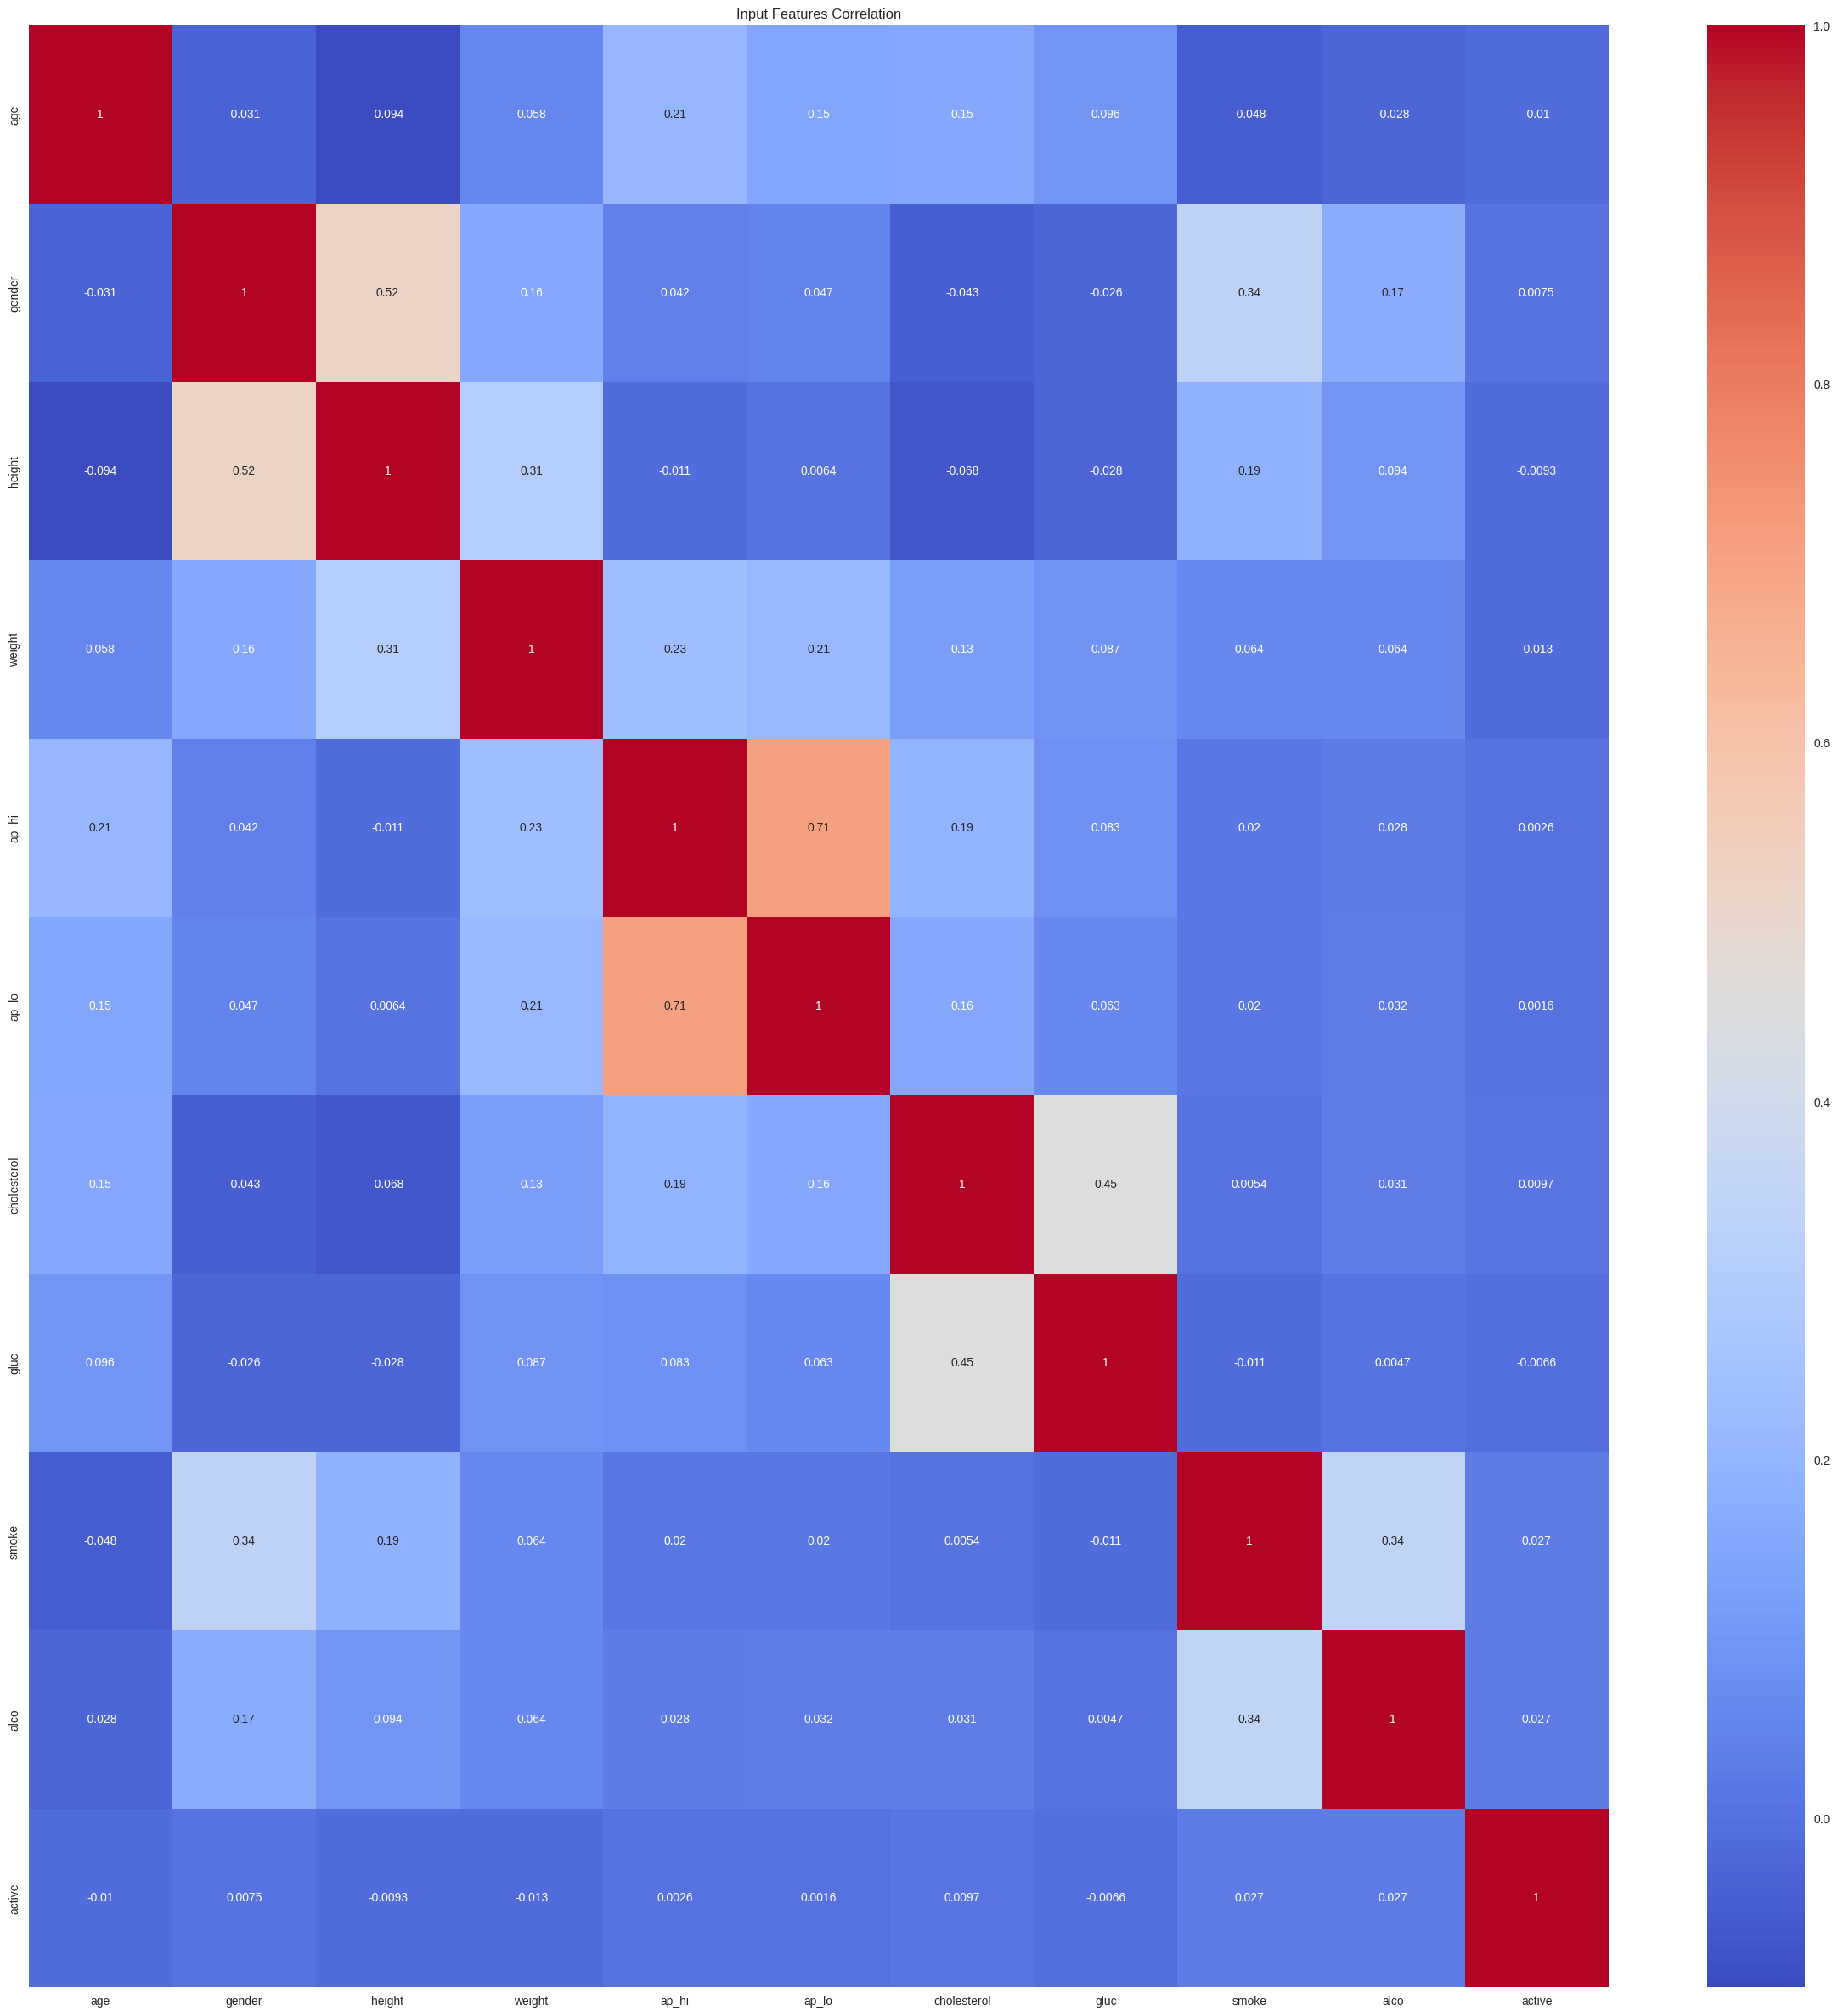

In [ ]:
plt.figure(figsize=(30, 30))

plt.title("Input Features Correlation")

sns.heatmap(
    df[INPUT_FEATURES].corr(),
    annot=True,
    cmap='coolwarm',
    )

plt.show()

# **Correlation Analysis**

,Pearson r,Spearman rho
ap_hi,0.432,0.441
ap_lo,0.336,0.339
age,0.237,0.233
cholesterol,0.218,0.212
weight,0.162,0.159
gluc,0.086,0.087
active,-0.038,-0.038
height,-0.028,-0.027
smoke,-0.022,-0.022
alco,-0.012,-0.012


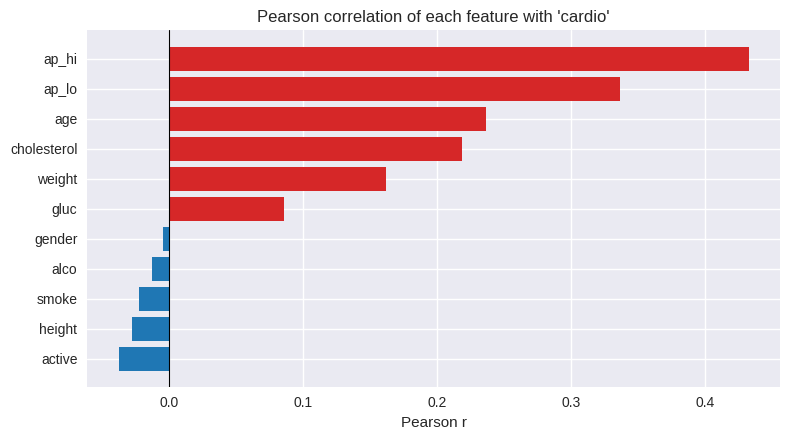

Strongest feature-feature correlations:


,Feature 1,Feature 2,|r|
0,ap_hi,ap_lo,0.706
1,gender,height,0.517
2,cholesterol,gluc,0.450
3,smoke,alco,0.342
4,gender,smoke,0.337
5,height,weight,0.306
6,weight,ap_hi,0.233
7,weight,ap_lo,0.214



Class balance:


,count,percent %
cardio,,
0,31614,50.6
1,30861,49.4


In [ ]:
# Correlation of every feature with the target
# Pearson with a binary target shows us point-biserial correlation
# Spearman is shown too because several features are ordinal
corr_data = df[INPUT_FEATURES + [TARGET]]

target_corr = pd.DataFrame({
    'Pearson r': corr_data.corr(method='pearson')[TARGET].drop(TARGET),
    'Spearman rho': corr_data.corr(method='spearman')[TARGET].drop(TARGET),
}).sort_values('Pearson r', key=abs, ascending=False)

display(target_corr.round(3))

plot_corr = target_corr['Pearson r'].sort_values()
plt.figure(figsize=(8, 4.5))
plt.barh(plot_corr.index, plot_corr.values,
         color=np.where(plot_corr.values > 0, 'tab:red', 'tab:blue'))
plt.axvline(0, color='k', lw=0.8)
plt.title(f"Pearson correlation of each feature with '{TARGET}'")
plt.xlabel("Pearson r")
plt.tight_layout()
plt.show()

# Multicollinearity: strongest feature-feature correlations
abs_corr = df[INPUT_FEATURES].corr().abs()
cols = abs_corr.columns
pairs = pd.DataFrame(
    [(cols[i], cols[j], abs_corr.iloc[i, j])
     for i in range(len(cols)) for j in range(i + 1, len(cols))],
    columns=['Feature 1', 'Feature 2', '|r|']
).sort_values('|r|', ascending=False).reset_index(drop=True)

print("Strongest feature-feature correlations:")
display(pairs.head(8).round(3))

# Class balance (needed for the class-imbalance analysis)
balance = df[TARGET].value_counts().rename('count').to_frame()
balance['percent %'] = 100 * balance['count'] / balance['count'].sum()
print("\nClass balance:")
display(balance.round(2))


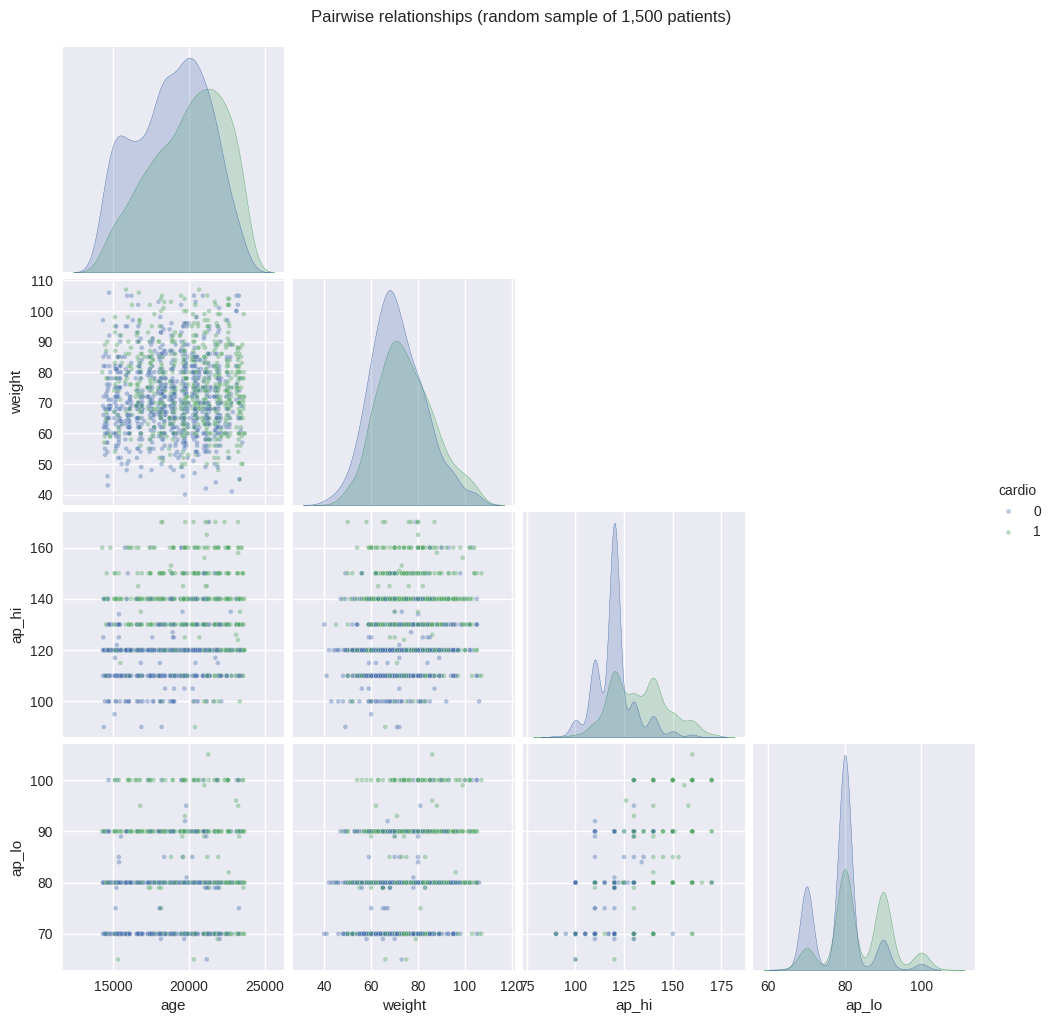

In [ ]:
# Pairwise relationships on a random sample
pair_cols = ['age', 'weight', 'ap_hi', 'ap_lo']
pair_sample = df[pair_cols + [TARGET]].sample(1500, random_state=42)

sns.pairplot(pair_sample, hue=TARGET, corner=True, plot_kws={'alpha': 0.4, 's': 12})
plt.suptitle("Pairwise relationships (random sample of 1,500 patients)", y=1.02)
plt.show()


### Observations: correlation analysis

* **Blood pressure dominates.** `ap_hi` and `ap_lo` have the strongest linear association with `cardio`, which agrees with the ANOVA F-scores computed later (the largest F-values belong to the blood-pressure features `ap_hi`, `map`, `pulse_pressure` and `ap_lo`).
* **Age, cholesterol and weight** come next, followed by glucose. Smoking, alcohol and physical activity are only weakly related to the target on their own.
* **`gender` is essentially uninformative** by itself (ANOVA p = 0.37 on the training set).
* **Multicollinearity:** `ap_hi` and `ap_lo` are correlated with each other (check the pair table above for the exact value). The engineered `map` and `pulse_pressure` are linear combinations of them, so linear models would suffer from collinearity; tree-based models and RBF-SVMs are less affected.
* **Class balance:** the two classes are almost perfectly balanced, so accuracy is a meaningful metric and no resampling is required (see the class-balance table above).

> Compare these statements with the numbers in the tables and quote the exact values in the report.


# **Feature Engineering**

In [ ]:
INPUT_FEATURES

['age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active']

In [ ]:
df.head(5)

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,21914,1,151,67.0,120,80,2,2,0,0,0,0


Age in years

In [ ]:
df['age_years'] = (df['age'] / 365).round().astype(int)

Height in meters

In [ ]:
df['height_m'] = df['height'] / 100

BMI

In [ ]:
df['bmi'] = df['weight'] / (df['height_m'] ** 2)

Pulse pressure

In [ ]:
df['pulse_pressure'] = df['ap_hi'] - df['ap_lo']

Health index

In [ ]:
df['health_index'] = (df['active'] * 1) - (df['smoke'] * 0.5) - (df['alco'] * 0.5)

Cholestrol glucose interaction

In [ ]:
df['cholesterol_gluc_interaction'] = df['cholesterol'] * df['gluc']

Mean Arterial Pressure (MAP)

In [ ]:
df['map'] = (df['ap_hi'] + 2 * df['ap_lo']) / 3

BMI category

In [ ]:
df['bmi_category'] = pd.cut(
    df['bmi'],
    bins=[0, 18.5, 25, 30, np.inf],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
)

Hypertension-stage

In [ ]:
def bp_category(row):
    systolic = row['ap_hi']
    diastolic = row['ap_lo']
    if systolic < 120 and diastolic < 80:
        return 'Normal'
    elif systolic < 130 and diastolic < 80:
        return 'Elevated'
    elif systolic < 140 and diastolic < 90:
        return 'Stage 1'
    else:
        return 'Stage 2'

df['hypertension_stage'] = df.apply(bp_category, axis=1)

In [ ]:
new_features = [
    'age_years', 'bmi', 'pulse_pressure', 'health_index',
    'cholesterol_gluc_interaction', 'map', 'bmi_category', 'hypertension_stage'
]

INPUT_FEATURES = INPUT_FEATURES + [f for f in new_features if f not in INPUT_FEATURES]

Dropping unwanted values

In [ ]:
df = drop_unwanted_features(df, 'age')
df = drop_unwanted_features(df, 'height')


Dropping feature: age

Dropping feature: height


In [ ]:
df.columns

Index(['gender', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke',
       'alco', 'active', 'cardio', 'age_years', 'height_m', 'bmi',
       'pulse_pressure', 'health_index', 'cholesterol_gluc_interaction', 'map',
       'bmi_category', 'hypertension_stage'],
      dtype='object')

In [ ]:
INPUT_FEATURES = [
    'gender', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc',
    'smoke', 'alco', 'active', 'age_years', 'bmi', 'pulse_pressure',
    'health_index', 'cholesterol_gluc_interaction', 'map',
    'bmi_category', 'hypertension_stage'
]

In [ ]:
INPUT_FEATURES

['gender',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'age_years',
 'bmi',
 'pulse_pressure',
 'health_index',
 'cholesterol_gluc_interaction',
 'map',
 'bmi_category',
 'hypertension_stage']

# **Feature selection**

Dataset-splitting

In [ ]:
#Dataset splitting
X_train, X_test, y_train, y_test = train_test_split(
    df[INPUT_FEATURES], df[TARGET],
    test_size=0.20,
    random_state=1234,
    stratify=df[TARGET]
)

print(f"{X_train.shape= }")
print(f"{y_train.shape= }")
print(f"{X_test.shape= }")
print(f"{y_test.shape= }")

#Encoding categorical engineered features
CATEGORICAL_TO_ENCODE = ['bmi_category', 'hypertension_stage']

X_train_encoded = pd.get_dummies(X_train, columns=CATEGORICAL_TO_ENCODE, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=CATEGORICAL_TO_ENCODE, drop_first=True)

# Align test set columns to train set (handles any category missing from one split)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

X_train.shape= (49980, 17)
y_train.shape= (49980,)
X_test.shape= (12495, 17)
y_test.shape= (12495,)


Correlation matrix after feature engineering

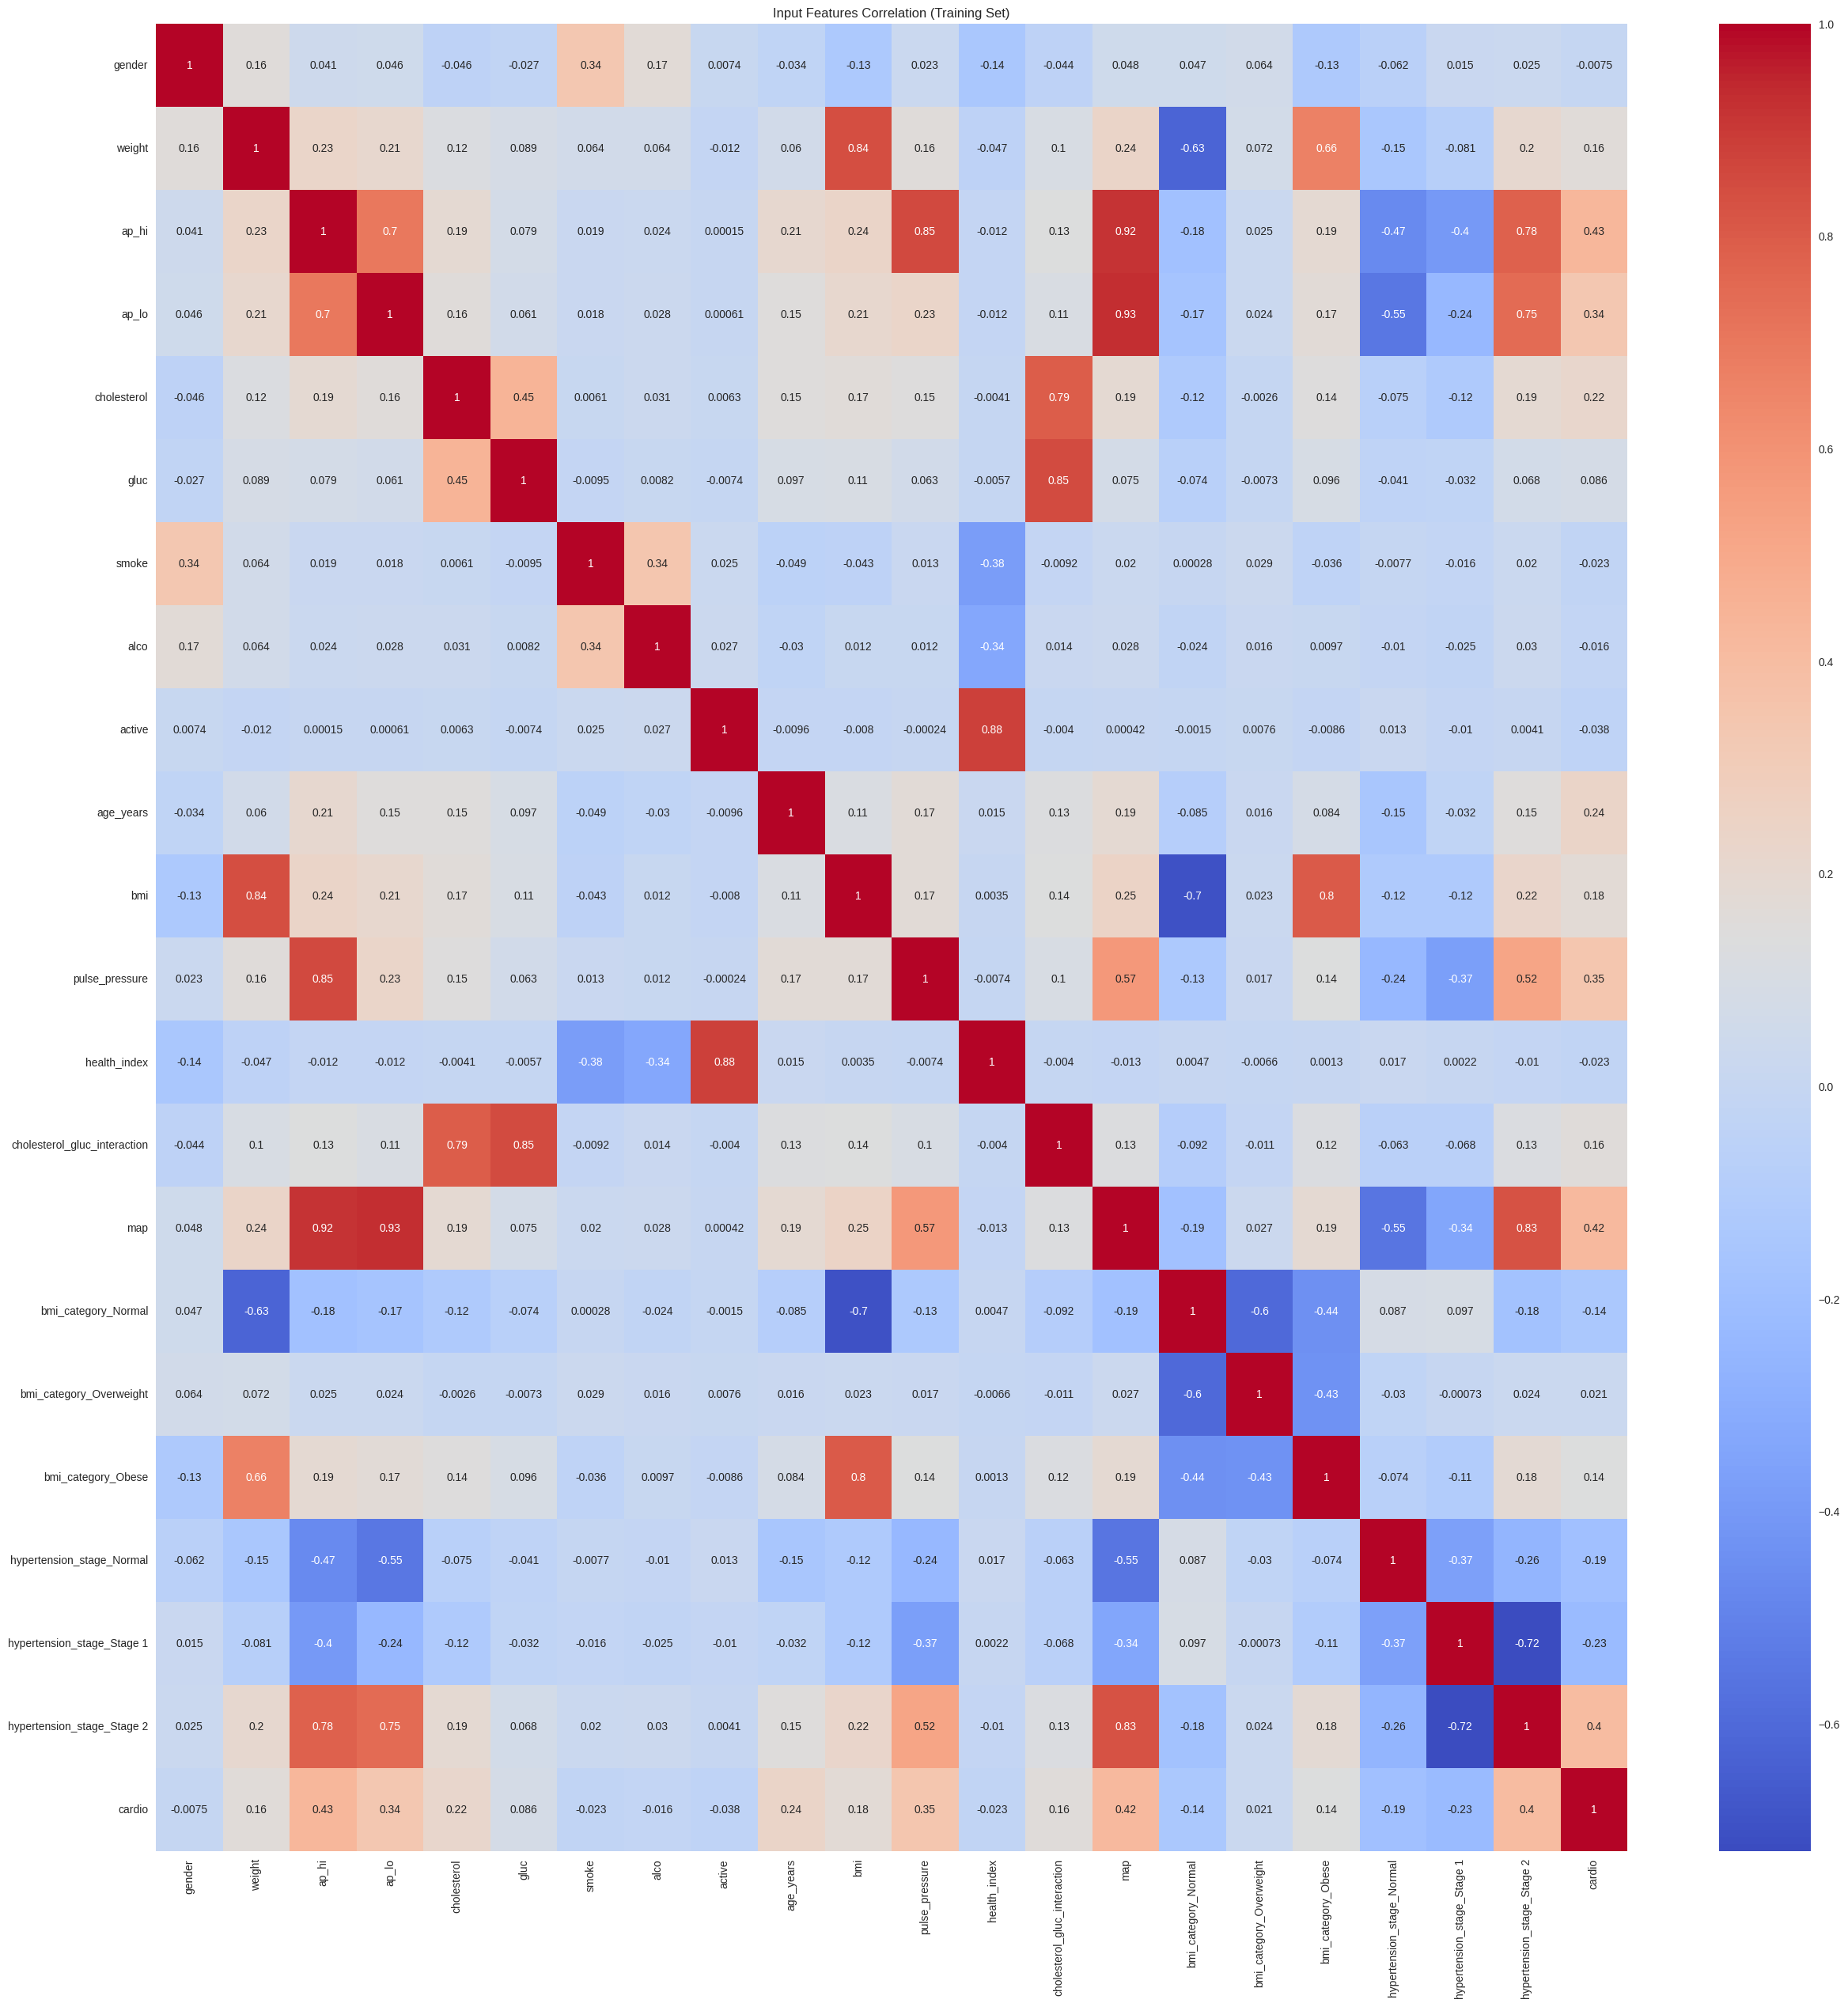

gender                             : F-value =    2.829, p-value = 0.0926
weight                             : F-value = 1321.315, p-value = 0.0000
ap_hi                              : F-value = 11645.717, p-value = 0.0000
ap_lo                              : F-value = 6481.649, p-value = 0.0000
cholesterol                        : F-value = 2522.143, p-value = 0.0000
gluc                               : F-value =  370.746, p-value = 0.0000
smoke                              : F-value =   26.783, p-value = 0.0000
alco                               : F-value =   13.124, p-value = 0.0003
active                             : F-value =   74.090, p-value = 0.0000
age_years                          : F-value = 2939.228, p-value = 0.0000
bmi                                : F-value = 1649.359, p-value = 0.0000
pulse_pressure                     : F-value = 6817.953, p-value = 0.0000
health_index                       : F-value =   26.757, p-value = 0.0000
cholesterol_gluc_interaction       : 

In [ ]:
plt.figure(figsize=(30, 30))
plt.title("Input Features Correlation (Training Set)")

sns.heatmap(
    pd.concat([X_train_encoded, y_train], axis=1).corr(),
    annot=True,
    cmap='coolwarm'
)
plt.show()

#Feature selection (ANOVA F-test on training set only)
f_values, p_values = f_classif(X_train_encoded, y_train)

for feature, f_val, p_val in zip(X_train_encoded.columns, f_values, p_values):
    print(f"{feature:35s}: F-value = {f_val:8.3f}, p-value = {p_val:.4f}")

In [ ]:
#Finalize selected features
ALPHA = 0.05
SELECTED_FEATURES = [
    feature for feature, p in zip(X_train_encoded.columns, p_values) if p < ALPHA
]

print(f"Selected {len(SELECTED_FEATURES)} of {X_train_encoded.shape[1]} features at alpha={ALPHA}:")
print(SELECTED_FEATURES)

X_train_selected = X_train_encoded[SELECTED_FEATURES]
X_test_selected = X_test_encoded[SELECTED_FEATURES]

Selected 20 of 21 features at alpha=0.05:
['weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'bmi', 'pulse_pressure', 'health_index', 'cholesterol_gluc_interaction', 'map', 'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese', 'hypertension_stage_Normal', 'hypertension_stage_Stage 1', 'hypertension_stage_Stage 2']


### Feature selection: ranking by three methods

The ANOVA F-test keeps almost every feature (20 of 21 at α = 0.05), so on its own it does not reduce the feature set much. Therefore we use Recursive Feature Elimination (RFE, top k features), fitted inside every CV fold so that no information from the validation fold leaks into the selection. The table below puts the three criteria side by side (ANOVA F, mutual information, RFE) for the full training set.


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.feature_selection import RFE, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
import time
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

dt_probe = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
svm_probe = SVC(kernel="rbf", C=1.0, gamma="scale")

Running k-selection experiment (5-fold CV, training data only)...
Done in 12.5 min


f1         roc_auc        
                         mean     std    mean     std
model              k                                 
Decision Tree      3   0.6722  0.0099  0.7556  0.0079
                   5   0.7016  0.0102  0.7797  0.0072
                   7   0.7007  0.0069  0.7858  0.0083
                   8   0.7007  0.0069  0.7858  0.0083
                   10  0.7042  0.0104  0.7865  0.0086
                   12  0.7042  0.0103  0.7865  0.0084
                   15  0.6983  0.0106  0.7867  0.0084
                   18  0.6980  0.0105  0.7867  0.0084
                   21  0.6980  0.0105  0.7868  0.0085
SVM (8k subsample) 3   0.6762  0.0095  0.7450  0.0065
                   5   0.7015  0.0122  0.7691  0.0057
                   7   0.7059  0.0115  0.7785  0.0082
                   8   0.7049  0.0111  0.7803  0.0077
                   10  0.6959  0.0117  0.7784  0.0074
                   12  0.6952  0.0117  0.7793  0.0062
                   15  0.6959  0.0113  0.7795  0.0053
                   18  0.6956  0.0115  0.7775  0.0060
                   21  0.6945  0.0122  0.7767  0.0057

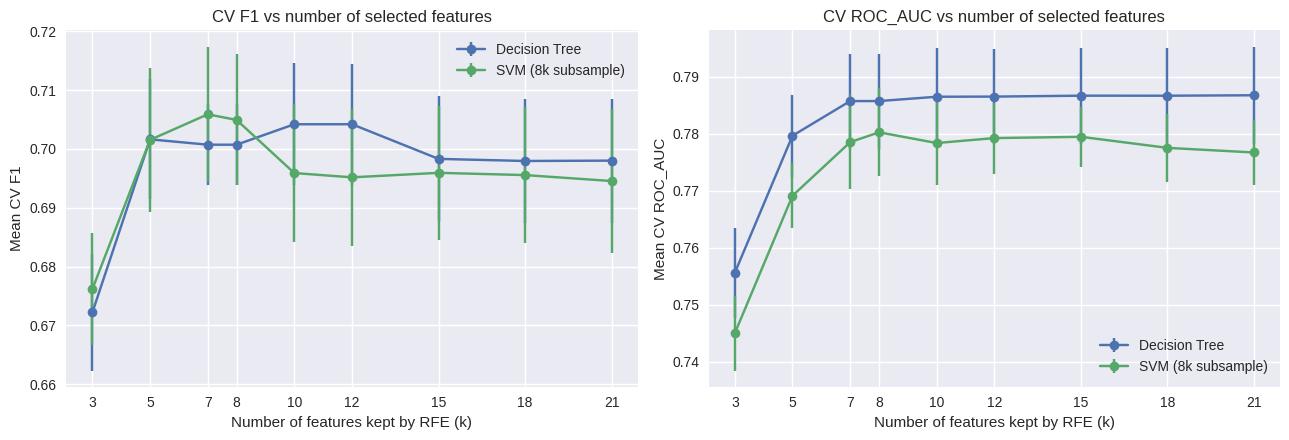

k with highest mean F1: 7  (F1 = 0.7033)
Threshold (best - 1 SD): 0.6947
Chosen k (smallest within 1 SD of best): 5


In [ ]:
K_VALUES = [3, 5, 7, 8, 10, 12, 15, 18, X_train_encoded.shape[1]]
SVM_TRAIN_ROWS = 8000          # SVM is slow, so train on a subsample of each fold's training part
cv_k = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def run_fold_k(fold_id, tr_idx, va_idx):
    X_tr, X_va = X_train_encoded.iloc[tr_idx], X_train_encoded.iloc[va_idx]
    y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]

    # Full RFE elimination order, fitted on the TRAINING part of the fold only
    rfe = RFE(
        estimator=RandomForestClassifier(n_estimators=50, random_state=42,
                                         class_weight="balanced", n_jobs=1),
        n_features_to_select=1, step=1
    ).fit(X_tr, y_tr)
    ranking = pd.Series(rfe.ranking_, index=X_tr.columns)

    sub_pos, _ = train_test_split(np.arange(len(y_tr)), train_size=SVM_TRAIN_ROWS,
                                  stratify=y_tr, random_state=42)

    rows = []
    for k in K_VALUES:
        cols = ranking.index[ranking <= k]          # the top-k features

        dt = clone(dt_probe).fit(X_tr[cols], y_tr)
        rows.append({"fold": fold_id, "k": k, "model": "Decision Tree",
                     "f1": f1_score(y_va, dt.predict(X_va[cols])),
                     "roc_auc": roc_auc_score(y_va, dt.predict_proba(X_va[cols])[:, 1])})

        svm = Pipeline([("scaler", StandardScaler()), ("model", clone(svm_probe))])
        svm.fit(X_tr[cols].iloc[sub_pos], y_tr.iloc[sub_pos])
        rows.append({"fold": fold_id, "k": k, "model": "SVM (8k subsample)",
                     "f1": f1_score(y_va, svm.predict(X_va[cols])),
                     "roc_auc": roc_auc_score(y_va, svm.decision_function(X_va[cols]))})
    return rows


t0 = time.time()
print("Running k-selection experiment (5-fold CV, training data only)...", flush=True)
out = Parallel(n_jobs=2)(
    delayed(run_fold_k)(i, tr, va)
    for i, (tr, va) in enumerate(cv_k.split(X_train_encoded, y_train), start=1)
)
k_results = pd.DataFrame([r for rows in out for r in rows])
print(f"Done in {(time.time() - t0) / 60:.1f} min")

# ---- summary table: mean +/- SD over 5 folds ----
k_summary = (k_results.groupby(["model", "k"])[["f1", "roc_auc"]]
             .agg(["mean", "std"]).round(4))
display(k_summary)

# ---- plot ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, metric in zip(axes, ["f1", "roc_auc"]):
    for name, g in k_results.groupby("model"):
        s = g.groupby("k")[metric].agg(["mean", "std"])
        ax.errorbar(s.index, s["mean"], yerr=s["std"], marker="o", capsize=3, label=name)
    ax.set_xlabel("Number of features kept by RFE (k)")
    ax.set_ylabel(f"Mean CV {metric.upper()}")
    ax.set_xticks(K_VALUES)
    ax.set_title(f"CV {metric.upper()} vs number of selected features")
    ax.legend()
plt.tight_layout()
plt.show()

# ---- decision rule: one-standard-deviation rule on the average F1 of both models ----
# (pick the SMALLEST k whose mean F1 is within 1 SD of the best k)
avg = (k_results.groupby(["k", "fold"])["f1"].mean()      # average of DT and SVM per fold
       .groupby("k").agg(["mean", "std"]))
best_mean_k = avg["mean"].idxmax()
threshold = avg.loc[best_mean_k, "mean"] - avg.loc[best_mean_k, "std"]
BEST_K = int(avg[avg["mean"] >= threshold].index.min())

print(f"k with highest mean F1: {best_mean_k}  (F1 = {avg.loc[best_mean_k, 'mean']:.4f})")
print(f"Threshold (best - 1 SD): {threshold:.4f}")
print(f"Chosen k (smallest within 1 SD of best): {BEST_K}")

,Feature,ANOVA F,ANOVA p,Mutual information,RFE rank (1 = kept),RFE selected
0,ap_hi,11645.7,0.0000,0.1138,1,True
1,map,10525.4,0.0000,0.0996,1,True
2,age_years,2939.2,0.0000,0.0318,1,True
3,bmi,1649.4,0.0000,0.0171,1,True
4,weight,1321.3,0.0000,0.0141,1,True
5,cholesterol_gluc_interaction,1247.2,0.0000,0.0211,2,False
6,hypertension_stage_Stage 2,9777.3,0.0000,0.0853,3,False
7,pulse_pressure,6818.0,0.0000,0.0742,3,False
8,health_index,26.8,0.0000,0.0004,3,False
9,ap_lo,6481.6,0.0000,0.0652,4,False


RFE-selected features: ['weight', 'ap_hi', 'age_years', 'bmi', 'map']


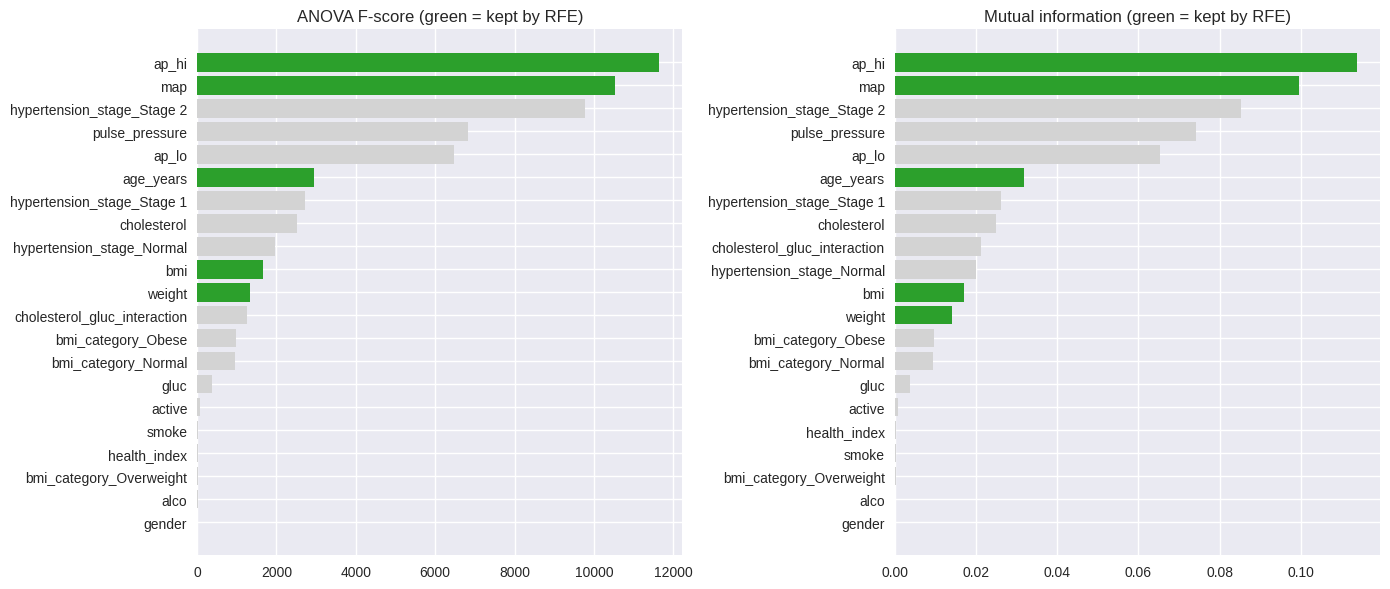

In [ ]:
def rfe_selector():
    """Same RFE configuration as in the Phase 3 CV pipelines (top-k features)."""
    return RFE(
        estimator=RandomForestClassifier(
            n_estimators=50, random_state=42,
            class_weight="balanced", n_jobs=1
        ),
        n_features_to_select=BEST_K,
        step=3
    )


# --- rankings on the TRAINING set only -------------------------
discrete_mask = (X_train_encoded.nunique() <= 10).values   # binary / ordinal columns
X_mi = X_train_encoded.astype(float).copy()
for col in X_mi.columns[discrete_mask]:
    X_mi[col] = pd.factorize(X_mi[col])[0]                  # integer codes for discrete columns
mi_values = mutual_info_classif(
    X_mi, y_train, discrete_features=discrete_mask, random_state=42
)

rfe_view = rfe_selector().fit(X_train_encoded, y_train)

selection_table = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "ANOVA F": f_values,
    "ANOVA p": p_values,
    "Mutual information": mi_values,
    "RFE rank (1 = kept)": rfe_view.ranking_,
    "RFE selected": rfe_view.support_,
}).sort_values(["RFE rank (1 = kept)", "ANOVA F"], ascending=[True, False]).reset_index(drop=True)

display(selection_table.style.format({"ANOVA F": "{:.1f}", "ANOVA p": "{:.4f}", "Mutual information": "{:.4f}"}))

print("RFE-selected features:", list(X_train_encoded.columns[rfe_view.support_]))

# --- visual comparison -----------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ordered = selection_table.sort_values("ANOVA F")
bar_colors = np.where(ordered["RFE selected"], "tab:green", "lightgray")

axes[0].barh(ordered["Feature"], ordered["ANOVA F"], color=bar_colors)
axes[0].set_title("ANOVA F-score (green = kept by RFE)")

ordered = selection_table.sort_values("Mutual information")
bar_colors = np.where(ordered["RFE selected"], "tab:green", "lightgray")
axes[1].barh(ordered["Feature"], ordered["Mutual information"], color=bar_colors)
axes[1].set_title("Mutual information (green = kept by RFE)")

plt.tight_layout()
plt.show()


### Original vs engineered vs selected features

Every score below is a 5-fold stratified CV score computed on the training set only. Two models are used:

* Decision Tree (depth 5, the best depth found later) on the full training set.
* RBF SVM on a stratified 10,000-row subsample of the training set. The full SVM takes about 4 minutes per fit, so the subsample keeps this comparison fast. Treat the SVM numbers as indicative.

age_years and height_m are plain unit conversions of the original age and height, so they count as original features.


Evaluating: Original features ...
Evaluating: Engineered features only ...
Evaluating: All (original + engineered) ...
Evaluating: ANOVA-selected (p < 0.05) ...
Evaluating: RFE top-5 (selected inside CV) ...


,Feature set,# features,DT F1,DT F1 SD,DT ROC-AUC,SVM F1 (10k subsample),SVM F1 SD,SVM ROC-AUC (10k subsample)
0,Original features,11,0.6968,0.0102,0.7866,0.7048,0.0102,0.7846
1,Engineered features only,11,0.6932,0.0092,0.7630,0.6858,0.0137,0.7576
2,All (original + engineered),21,0.6980,0.0105,0.7868,0.6993,0.0128,0.7792
3,ANOVA-selected (p < 0.05),20,0.6980,0.0105,0.7867,0.6994,0.0119,0.7792
4,RFE top-5 (selected inside CV),5,0.7016,0.0102,0.7797,0.7023,0.0132,0.7711


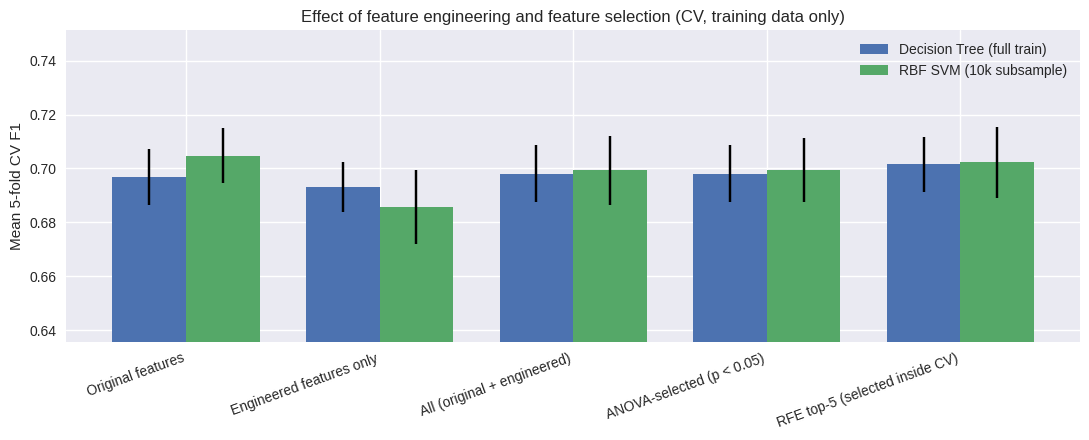

Decision Tree    | feature engineering (all - original): +0.0012 F1 | RFE selection (RFE-5 - all): +0.0036 F1
SVM (subsample)  | feature engineering (all - original): -0.0055 F1 | RFE selection (RFE-5 - all): +0.0030 F1


In [ ]:
cv_fs = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fs_scoring = {"f1": "f1", "roc_auc": "roc_auc", "accuracy": "accuracy"}


def score_feature_set(X, y, estimator, scale=False, use_rfe=False):
    """5-fold CV score of one feature set (selection/scaling are fitted inside each fold)."""
    steps = []
    if use_rfe:
        steps.append(("selector", rfe_selector()))
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", clone(estimator)))

    res = cross_validate(Pipeline(steps), X, y, cv=cv_fs, scoring=fs_scoring, n_jobs=2)
    return {
        "F1": res["test_f1"].mean(),
        "F1 SD": res["test_f1"].std(ddof=1),
        "ROC-AUC": res["test_roc_auc"].mean(),
        "Accuracy": res["test_accuracy"].mean(),
    }


# --- define the feature sets (all taken from the TRAINING split) ---
ORIGINAL_FEATURES = ['gender', 'age_years', 'weight', 'ap_hi', 'ap_lo',
                     'cholesterol', 'gluc', 'smoke', 'alco', 'active']
X_orig = X_train_encoded[ORIGINAL_FEATURES].copy()
X_orig['height_m'] = df.loc[X_train.index, 'height_m']

engineered_cols = [
    c for c in X_train_encoded.columns
    if c in ('bmi', 'pulse_pressure', 'health_index', 'cholesterol_gluc_interaction', 'map')
    or c.startswith(('bmi_category_', 'hypertension_stage_'))
]

RFE_LABEL = f"RFE top-{BEST_K} (selected inside CV)"

feature_sets = {
    "Original features":                 (X_orig, False),
    "Engineered features only":          (X_train_encoded[engineered_cols], False),
    "All (original + engineered)":       (X_train_encoded, False),
    "ANOVA-selected (p < 0.05)":         (X_train_encoded[SELECTED_FEATURES], False),
    f"RFE top-{BEST_K} (selected inside CV)":   (X_train_encoded, True),
}

sub_idx, _ = train_test_split(
    np.arange(len(y_train)), train_size=min(10000, int(0.8 * len(y_train))),
    stratify=y_train, random_state=42
)

rows = []
for set_name, (X_set, use_rfe) in feature_sets.items():
    print(f"Evaluating: {set_name} ...", flush=True)
    dt_res = score_feature_set(X_set, y_train, dt_probe, scale=False, use_rfe=use_rfe)
    svm_res = score_feature_set(X_set.iloc[sub_idx], y_train.iloc[sub_idx], svm_probe,
                                scale=True, use_rfe=use_rfe)
    rows.append({
        "Feature set": set_name,
        "# features": BEST_K if use_rfe else X_set.shape[1],
        "DT F1": dt_res["F1"], "DT F1 SD": dt_res["F1 SD"], "DT ROC-AUC": dt_res["ROC-AUC"],
        "SVM F1 (10k subsample)": svm_res["F1"], "SVM F1 SD": svm_res["F1 SD"],
        "SVM ROC-AUC (10k subsample)": svm_res["ROC-AUC"],
    })

fs_results_df = pd.DataFrame(rows)
display(fs_results_df.style.format({c: "{:.4f}" for c in fs_results_df.columns
                                    if c not in ("Feature set", "# features")}))

# --- plot ---
x = np.arange(len(fs_results_df))
w = 0.38
plt.figure(figsize=(11, 4.5))
plt.bar(x - w/2, fs_results_df["DT F1"], w, yerr=fs_results_df["DT F1 SD"], capsize=3, label="Decision Tree (full train)")
plt.bar(x + w/2, fs_results_df["SVM F1 (10k subsample)"], w, yerr=fs_results_df["SVM F1 SD"], capsize=3, label="RBF SVM (10k subsample)")
plt.xticks(x, fs_results_df["Feature set"], rotation=20, ha="right")
lo = min(fs_results_df["DT F1"].min(), fs_results_df["SVM F1 (10k subsample)"].min())
plt.ylim(max(0, lo - 0.05), None)
plt.ylabel("Mean 5-fold CV F1")
plt.title("Effect of feature engineering and feature selection (CV, training data only)")
plt.legend()
plt.tight_layout()
plt.show()

# --- automatic read-out for the discussion section ---
def _f1(set_name, col):
    return fs_results_df.loc[fs_results_df["Feature set"] == set_name, col].iloc[0]

for label, col in [("Decision Tree", "DT F1"), ("SVM (subsample)", "SVM F1 (10k subsample)")]:
    d_fe = _f1("All (original + engineered)", col) - _f1("Original features", col)
    d_fs = _f1(RFE_LABEL, col) - _f1("All (original + engineered)", col)
    print(f"{label:16s} | feature engineering (all - original): {d_fe:+.4f} F1"
          f" | RFE selection (RFE-{BEST_K} - all): {d_fs:+.4f} F1")

### Observations: feature sets

Use the table and the automatic read-out above to answer two questions from the brief:

1. **Did feature engineering help?** Compare *Original features* with *All (original + engineered)*. Differences smaller than one fold-to-fold standard deviation (`F1 SD`) should be reported as "no clear improvement".
2. **Did feature selection help?** Compare *All* with *ANOVA-selected* and *RFE top-k*. Selection mainly buys a **simpler, faster and more interpretable model**; an unchanged F1 with half the features is already a good result.

Note that the engineered blood-pressure features (`map`, `pulse_pressure`, hypertension stage) are linear combinations or thresholds of `ap_hi`/`ap_lo`, so a Decision Tree can approximate them on its own. A small or zero gain for tree models is therefore expected and should be discussed rather than hidden.


Before scaling (raw feature values)

In [ ]:
df.describe()

,gender,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,pulse_pressure,health_index,cholesterol_gluc_interaction,map
count,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000,62475.000000
mean,1.348635,73.183247,126.424474,81.699080,1.357871,1.220744,0.086371,0.052181,0.804322,0.493974,53.407779,1.644054,27.121186,44.725394,0.735046,1.830140,96.607544
std,0.476542,12.272597,14.290699,7.673797,0.675308,0.567705,0.280913,0.222393,0.396725,0.499968,6.740363,0.075320,4.568125,10.404568,0.441294,1.860759,9.125575
min,1.000000,40.000000,90.000000,65.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,39.000000,1.430000,13.520822,5.000000,-1.000000,1.000000,73.333333
25%,1.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,49.000000,1.590000,23.875115,40.000000,0.500000,1.000000,93.333333
50%,1.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,54.000000,1.650000,26.234568,40.000000,1.000000,1.000000,93.333333
75%,2.000000,81.000000,140.000000,90.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,58.000000,1.700000,29.760838,50.000000,1.000000,2.000000,103.333333
max,2.000000,107.000000,170.000000,105.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000,65.000000,1.860000,50.891795,103.000000,1.000000,9.000000,126.000000


Standardisation (z-score, `StandardScaler`) happens after EDA so the visualisations keep real units, and after feature engineering so engineered values are not distorted. The scaler is **fitted on the training set only** and then applied to the test set, which avoids data leakage. Binary/ordinal columns are not scaled.

In [ ]:
NON_SCALE_FEATURES = ['gluc', 'alco', 'smoke', 'cholesterol', 'active']

cols_to_scale = [
    col for col in X_train_selected.columns
    if col not in NON_SCALE_FEATURES
    and not col.startswith('bmi_category_')
    and not col.startswith('hypertension_stage_')
]

standard_scaler = StandardScaler()

X_train_scaled = X_train_selected.copy()
X_test_scaled = X_test_selected.copy()

X_train_scaled[cols_to_scale] = standard_scaler.fit_transform(X_train_selected[cols_to_scale])
X_test_scaled[cols_to_scale] = standard_scaler.transform(X_test_selected[cols_to_scale])

print(f"Scaled columns: {cols_to_scale}")


Scaled columns: ['weight', 'ap_hi', 'ap_lo', 'age_years', 'bmi', 'pulse_pressure', 'health_index', 'cholesterol_gluc_interaction', 'map']


After scaling (training set)

In [ ]:
X_train_scaled.describe()

,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,age_years,bmi,pulse_pressure,health_index,cholesterol_gluc_interaction,map
count,4.998000e+04,4.998000e+04,4.998000e+04,49980.000000,49980.000000,49980.000000,49980.000000,49980.000000,4.998000e+04,4.998000e+04,4.998000e+04,4.998000e+04,4.998000e+04,4.998000e+04
mean,1.689067e-15,4.835046e-16,1.947666e-16,1.357283,1.220328,0.086415,0.051961,0.804342,-2.869609e-16,-3.308189e-16,-1.872318e-16,-1.236839e-16,6.941226e-17,7.236575e-16
std,1.000010e+00,1.000010e+00,1.000010e+00,0.674842,0.567248,0.280978,0.221950,0.396711,1.000010e+00,1.000010e+00,1.000010e+00,1.000010e+00,1.000010e+00,1.000010e+00
min,-2.703464e+00,-2.544777e+00,-2.171049e+00,1.000000,1.000000,0.000000,0.000000,0.000000,-2.139657e+00,-2.978836e+00,-3.807085e+00,-3.929827e+00,-4.459809e-01,-2.546834e+00
25%,-6.635855e-01,-4.473203e-01,-2.187174e-01,1.000000,1.000000,0.000000,0.000000,1.000000,-6.567079e-01,-7.068627e-01,-4.522008e-01,-5.325837e-01,-4.459809e-01,-3.562886e-01
50%,-9.241959e-02,-4.473203e-01,-2.187174e-01,1.000000,1.000000,0.000000,0.000000,1.000000,8.476665e-02,-1.893657e-01,-4.522008e-01,5.998308e-01,-4.459809e-01,-3.562886e-01
75%,6.419365e-01,9.509840e-01,1.082837e+00,1.000000,1.000000,0.000000,0.000000,1.000000,6.779463e-01,5.838995e-01,5.063377e-01,5.998308e-01,9.323545e-02,7.389839e-01
max,2.763410e+00,3.048441e+00,3.035169e+00,3.000000,3.000000,1.000000,1.000000,1.000000,1.716011e+00,5.221227e+00,5.586591e+00,5.998308e-01,3.867750e+00,3.221601e+00


# **MODEL TRAINING**

In [ ]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score


# #Train the SVM model
# svm_model = SVC(kernel='linear', C=1.0)
# svm_model.fit(X_train_scaled, y_train)

# #Predict and evaluate
# y_pred = svm_model.predict(X_test_scaled)
# print("Accuracy:", accuracy_score(y_test, y_pred))
# print("Recall:", recall_score(y_test, y_pred))
# print("F1:", f1_score(y_test, y_pred))
# print("Precision:", precision_score(y_test, y_pred))
# print("Roc Auc:", roc_auc_score(y_test, y_pred))

# PHASE 3:

In [ ]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state= 42
)

print("Number of folds:", cv.get_n_splits())

Number of folds: 5


In [ ]:
X_cv = X_train_encoded
y_cv = y_train

print("Features:", X_cv.shape[1])
print("Samples:", X_cv.shape[0])

Features: 21
Samples: 49980


In [ ]:
N_FEATURES = X_train_encoded.shape[1]
print("Total available features:", N_FEATURES)

Total available features: 21


In [ ]:
# 5-Fold CV and Hyperparameter Search
# Models: Decision Tree and SVM
# # Feature selection: RFE with a Random Forest estimato
# Selection criterion: Mean validation F1-score

import os
import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix,
    make_scorer
)

# 1. Prepare training data ONLY for cross-validation
X_cv = X_train_encoded.copy()
y_cv = pd.Series(y_train, index=X_cv.index).astype(int)

# The test set is NOT used during hyperparameter selection.
OUTPUT_DIR = "/content/OUTPUT_DIR"
os.makedirs(OUTPUT_DIR, exist_ok=True)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
# 2. Define evaluation metrics
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return tn / (tn + fp) if (tn + fp) > 0 else 0.0


scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, zero_division=0
    ),
    "recall": make_scorer(
        recall_score, zero_division=0
    ),
    "specificity": make_scorer(specificity_score),
    "f1": make_scorer(
        f1_score, zero_division=0
    ),
    "roc_auc": "roc_auc",
    "mcc": make_scorer(matthews_corrcoef)
}


In [ ]:
# 3. Build leakage-safe pipelines
# Feature selection is fitted separately inside every fold.
# Scaling is included for SVM, but not Decision Tree.
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier


def make_pipeline(model, scale=False):

    steps = [
        (
            "selector",
            RFE(
                estimator=RandomForestClassifier(
                    n_estimators=200,
                    random_state=42,
                    class_weight="balanced",
                    n_jobs=-1
                ),
                n_features_to_select=min(BEST_K, X_cv.shape[1]),
                step=1
            )
        )
    ]

    # Scale selected features for SVM only
    if scale:
        steps.append(("scaler", StandardScaler()))

    steps.append(("model", model))

    return Pipeline(steps)


In [ ]:
# 4. Define FOUR configurations for each model
decision_tree_configs = {
    "DT depth 5": DecisionTreeClassifier(
        max_depth=5, random_state=42,
        class_weight="balanced"
    ),
    "DT depth 10": DecisionTreeClassifier(
        max_depth=10, random_state=42,
        class_weight="balanced"
    ),
    "DT depth 15": DecisionTreeClassifier(
        max_depth=15, random_state=42,
        class_weight="balanced"
    ),
    "DT depth 20": DecisionTreeClassifier(
        max_depth=20, random_state=42,
        class_weight="balanced"
    )
}

svm_configs = {
    "Linear SVM": SVC(
        kernel="linear", C=1.0
    ),
    "RBF SVM": SVC(
        kernel="rbf", C=1.0, gamma="scale"
    ),
    "Polynomial SVM": SVC(
        kernel="poly", C=1.0, degree=3,
        gamma="scale"
    ),
    "Sigmoid SVM": SVC(
        kernel="sigmoid", C=1.0,
        gamma="scale"
    )
}

In [ ]:
# 5. Evaluate every configuration using 5-fold CV
# Optimised RFE for faster execution

import time
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

all_results = []
best_pipelines = {}
best_configurations = {}

model_groups = {
    "Decision Tree": (decision_tree_configs, False),
    "SVM": (svm_configs, True)
}

# Evaluate configurations
for group_name, (configs, scale) in model_groups.items():

    group_results = []

    print(f"\n{'=' * 60}")
    print(f"Searching configurations: {group_name}")
    print(f"{'=' * 60}", flush=True)

    for config_name, estimator in configs.items():

        print(
            f"\nRunning: {group_name} — {config_name}",
            flush=True
        )

        # Build pipeline with faster RFE
        steps = [
            (
                "selector",
                RFE(
                    estimator=RandomForestClassifier(
                        n_estimators=50,
                        random_state=42,
                        class_weight="balanced",
                        n_jobs=1
                    ),
                    n_features_to_select=min(BEST_K, X_cv.shape[1]),
                    step=3
                )
            )
        ]

        # Scale features for SVM
        if scale:
            steps.append(("scaler", StandardScaler()))

        steps.append(("model", clone(estimator)))

        pipeline = Pipeline(steps)

        start_time = time.time()

        # Five-fold cross-validation
        cv_results = cross_validate(
            pipeline,
            X_cv,
            y_cv,
            cv=cv,
            scoring=scoring,
            return_train_score=False,
            n_jobs=2,
            error_score="raise"
        )

        elapsed = time.time() - start_time

        # Collect metrics
        result = {
            "Model Group": group_name,
            "Configuration": config_name,
            "Mean CV Accuracy": cv_results["test_accuracy"].mean(),
            "Mean CV Precision": cv_results["test_precision"].mean(),
            "Mean CV Recall": cv_results["test_recall"].mean(),
            "Mean CV Specificity": cv_results["test_specificity"].mean(),
            "Mean CV F1": cv_results["test_f1"].mean(),
            "Mean CV ROC-AUC": cv_results["test_roc_auc"].mean(),
            "Mean CV MCC": cv_results["test_mcc"].mean(),
            "SD CV F1": cv_results["test_f1"].std(ddof=1),
            "Runtime (seconds)": elapsed
        }

        group_results.append(result)
        all_results.append(result)

        print(
            f"Completed: {config_name} | "
            f"Mean F1 = {result['Mean CV F1']:.4f} | "
            f"Time = {elapsed:.1f}s",
            flush=True
        )

    # Select best configuration using mean CV F1
    group_df = pd.DataFrame(group_results)
    group_df = group_df.sort_values(
        "Mean CV F1",
        ascending=False
    )

    best_name = group_df.iloc[0]["Configuration"]
    best_estimator = configs[best_name]

    # Save the best pipeline for later final fitting
    best_steps = [
        (
            "selector",
            RFE(
                estimator=RandomForestClassifier(
                    n_estimators=50,
                    random_state=42,
                    class_weight="balanced",
                    n_jobs=1
                ),
                n_features_to_select=min(BEST_K, X_cv.shape[1]),
                step=3
            )
        )
    ]

    if scale:
        best_steps.append(("scaler", StandardScaler()))

    best_steps.append(("model", clone(best_estimator)))

    best_pipelines[group_name] = Pipeline(best_steps)
    best_configurations[group_name] = best_name

    print(f"\nBest {group_name}: {best_name}")
    print(
        f"Mean CV F1: "
        f"{group_df.iloc[0]['Mean CV F1']:.4f}"
    )

# Display and save all CV results
cv_results_df = pd.DataFrame(all_results)

cv_results_df = cv_results_df.sort_values(
    ["Model Group", "Mean CV F1"],
    ascending=[True, False]
).reset_index(drop=True)

display(cv_results_df)

cv_results_df.to_csv(
    "hyperparameter_cv_results.csv",
    index=False
)

print("\nCross-validation results saved to hyperparameter_cv_results.csv")
print("\nBest configurations:")
for group_name, config_name in best_configurations.items():
    print(f"{group_name}: {config_name}")


Searching configurations: Decision Tree

Running: Decision Tree — DT depth 5
Completed: DT depth 5 | Mean F1 = 0.7016 | Time = 148.1s

Running: Decision Tree — DT depth 10
Completed: DT depth 10 | Mean F1 = 0.6957 | Time = 110.8s

Running: Decision Tree — DT depth 15
Completed: DT depth 15 | Mean F1 = 0.6746 | Time = 109.3s

Running: Decision Tree — DT depth 20
Completed: DT depth 20 | Mean F1 = 0.6550 | Time = 107.9s

Best Decision Tree: DT depth 5
Mean CV F1: 0.7016

Searching configurations: SVM

Running: SVM — Linear SVM
Completed: Linear SVM | Mean F1 = 0.6704 | Time = 451.7s

Running: SVM — RBF SVM
Completed: RBF SVM | Mean F1 = 0.7010 | Time = 595.2s

Running: SVM — Polynomial SVM
Completed: Polynomial SVM | Mean F1 = 0.6413 | Time = 493.7s

Running: SVM — Sigmoid SVM
Completed: Sigmoid SVM | Mean F1 = 0.6091 | Time = 472.5s

Best SVM: RBF SVM
Mean CV F1: 0.7010


,Model Group,Configuration,Mean CV Accuracy,Mean CV Precision,Mean CV Recall,Mean CV Specificity,Mean CV F1,Mean CV ROC-AUC,Mean CV MCC,SD CV F1,Runtime (seconds)
0,Decision Tree,DT depth 5,0.716967,0.731877,0.674025,0.758887,0.701629,0.779678,0.434767,0.010190,148.079211
1,Decision Tree,DT depth 10,0.710064,0.722387,0.670987,0.748211,0.695688,0.763001,0.420645,0.007330,110.788655
2,Decision Tree,DT depth 15,0.686214,0.691540,0.658431,0.713337,0.674563,0.713509,0.372409,0.007948,109.303759
3,Decision Tree,DT depth 20,0.661084,0.658793,0.651262,0.670673,0.654992,0.664842,0.322013,0.003420,107.905899
4,SVM,RBF SVM,0.719328,0.739765,0.666167,0.771223,0.701018,0.766741,0.440063,0.006285,595.193017
5,SVM,Linear SVM,0.711465,0.769283,0.594070,0.826065,0.670388,0.776383,0.432446,0.007822,451.722278
6,SVM,Polynomial SVM,0.702361,0.792234,0.538742,0.862086,0.641322,0.762795,0.424299,0.009206,493.688506
7,SVM,Sigmoid SVM,0.613866,0.609184,0.609057,0.618560,0.609114,0.647216,0.227622,0.002482,472.534042



Cross-validation results saved to hyperparameter_cv_results.csv

Best configurations:
Decision Tree: DT depth 5
SVM: RBF SVM


In [ ]:
# 6. Refit the selected configurations on the full
# training set, then evaluate each ONCE on the test set.

X_test_final = X_test_encoded.copy()
y_test_final = pd.Series(y_test).astype(int).to_numpy()

def get_positive_scores(fitted_pipeline, X):
    """Get continuous scores for positive class 1."""
    if hasattr(fitted_pipeline, "decision_function"):
        return fitted_pipeline.decision_function(X)

    probabilities = fitted_pipeline.predict_proba(X)
    classes = fitted_pipeline.named_steps["model"].classes_
    positive_index = list(classes).index(1)

    return probabilities[:, positive_index]


test_results = []
fitted_best_models = {}

for group_name, pipeline in best_pipelines.items():

    # Fit only on the complete training set.
    pipeline.fit(X_cv, y_cv)

    # First and only use of the test set for this final evaluation.
    y_pred = pipeline.predict(X_test_final)
    y_score = get_positive_scores(
        pipeline, X_test_final
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test_final, y_pred, labels=[0, 1]
    ).ravel()

    test_result = {
        "Model": group_name,
        "Test Accuracy": accuracy_score(
            y_test_final, y_pred
        ),
        "Test Precision": precision_score(
            y_test_final, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test_final, y_pred, zero_division=0
        ),
        "Test Specificity": (
            tn / (tn + fp) if (tn + fp) > 0 else 0.0
        ),
        "Test F1": f1_score(
            y_test_final, y_pred, zero_division=0
        ),
        "Test ROC-AUC": roc_auc_score(
            y_test_final, y_score
        ),
        "Test MCC": matthews_corrcoef(
            y_test_final, y_pred
        )
    }

    test_results.append(test_result)
    fitted_best_models[group_name] = pipeline

    print(f"\nFinal test results: {group_name}")
    for metric, value in test_result.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}")

test_df = pd.DataFrame(test_results)
display(test_df)

test_df.to_csv(
    os.path.join(OUTPUT_DIR, "final_test_results.csv"),
    index=False
)


Final test results: Decision Tree
Test Accuracy: 0.7086
Test Precision: 0.7262
Test Recall: 0.6583
Test Specificity: 0.7577
Test F1: 0.6906
Test ROC-AUC: 0.7747
Test MCC: 0.4183

Final test results: SVM
Test Accuracy: 0.7124
Test Precision: 0.7304
Test Recall: 0.6623
Test Specificity: 0.7613
Test F1: 0.6947
Test ROC-AUC: 0.7603
Test MCC: 0.4260


,Model,Test Accuracy,Test Precision,Test Recall,Test Specificity,Test F1,Test ROC-AUC,Test MCC
0,Decision Tree,0.708603,0.726184,0.658296,0.757710,0.690575,0.774679,0.418263
1,SVM,0.712445,0.730391,0.662346,0.761347,0.694706,0.760314,0.425978


## 7. Validation performance of the four hyperparameter configurations

 The configuration with the highest mean CV F1 is selected for each model.


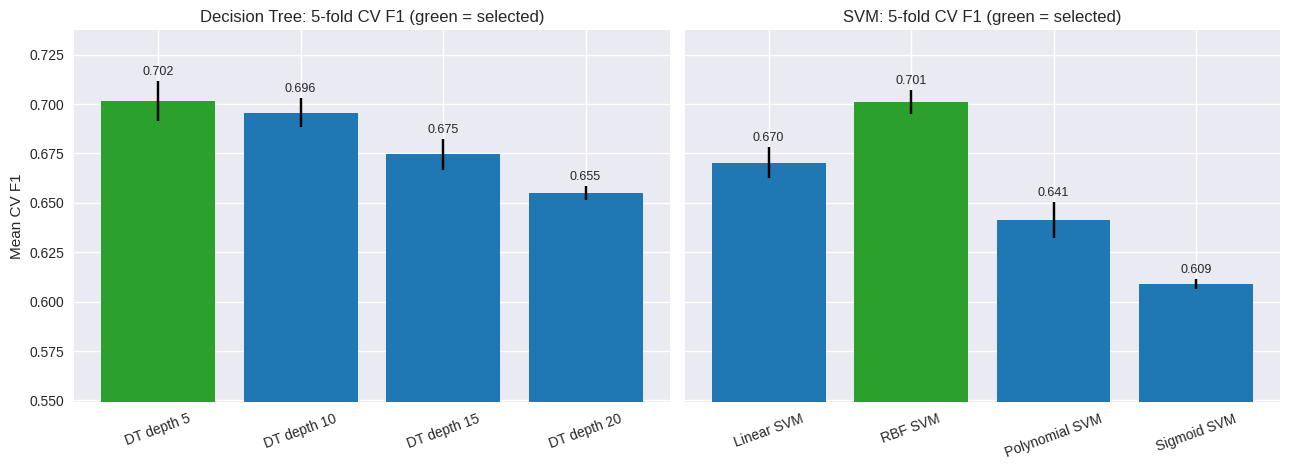

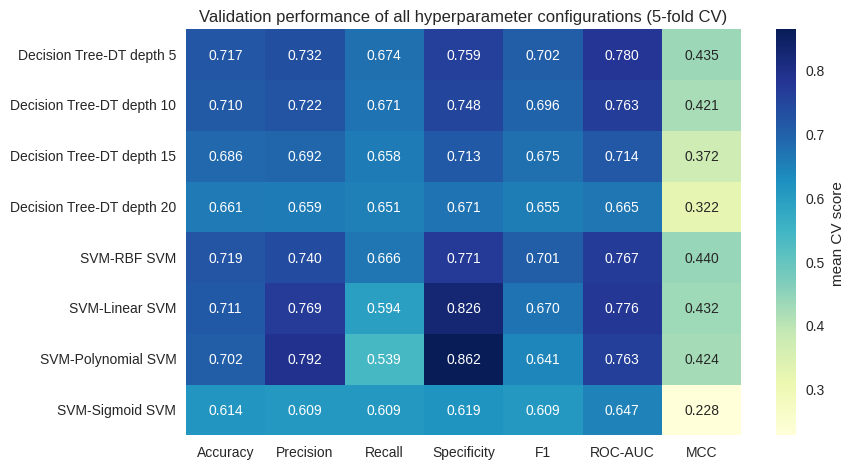

Selected configurations: {'Decision Tree': 'DT depth 5', 'SVM': 'RBF SVM'}


In [ ]:
import warnings
warnings.filterwarnings("ignore", message="X has feature names")

os.makedirs(OUTPUT_DIR, exist_ok=True)

def save_fig(filename):
    """Save the current figure into OUTPUT_DIR (300 dpi is good enough for the report)."""
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches="tight")


# mean CV F1 (+/- SD) of the four configurations of each model
config_order = {
    "Decision Tree": list(decision_tree_configs.keys()),
    "SVM": list(svm_configs.keys()),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (group_name, order) in zip(axes, config_order.items()):
    g = (cv_results_df[cv_results_df["Model Group"] == group_name]
         .set_index("Configuration").loc[order])
    best = best_configurations[group_name]
    colors = ["tab:green" if c == best else "tab:blue" for c in g.index]
    bars = ax.bar(g.index, g["Mean CV F1"], yerr=g["SD CV F1"], capsize=4, color=colors)
    for b, v, sd in zip(bars, g["Mean CV F1"], g["SD CV F1"]):
        ax.text(b.get_x() + b.get_width() / 2, v + sd + 0.003, f"{v:.3f}", ha="center", fontsize=9)
    ax.set_title(f"{group_name}: 5-fold CV F1 (green = selected)")
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(max(0, g["Mean CV F1"].min() - 0.06), (g["Mean CV F1"] + g["SD CV F1"]).max() + 0.03)
axes[0].set_ylabel("Mean CV F1")
plt.tight_layout()
save_fig("validation_f1_four_configs.png")
plt.show()

# all CV metrics for all 8 configurations
metric_cols = ["Mean CV Accuracy", "Mean CV Precision", "Mean CV Recall",
               "Mean CV Specificity", "Mean CV F1", "Mean CV ROC-AUC", "Mean CV MCC"]
heat = cv_results_df.set_index(["Model Group", "Configuration"])[metric_cols]
heat.columns = [c.replace("Mean CV ", "") for c in heat.columns]

plt.figure(figsize=(9, 4.8))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={"label": "mean CV score"})
plt.title("Validation performance of all hyperparameter configurations (5-fold CV)")
plt.ylabel("")
plt.tight_layout()
save_fig("validation_all_metrics_heatmap.png")
plt.show()

print("Selected configurations:", best_configurations)


## 8. Ensemble model: Soft Voting (Decision Tree + SVM)

**Design.** The ensemble combines Model 1 (best Decision Tree) and Model 2 (best SVM) by **soft voting**: the predicted probabilities of the two models are averaged (equal weights) and the class with the larger average probability is predicted.

**SVM probabilities.** An SVM outputs a signed margin, not a probability. We convert the margin into a probability with **Platt scaling**, a two-parameter logistic regression fitted on the margin values of the training data. This is the same idea that `SVC(probability=True)` uses internally, but that option refits the SVM with an additional internal 5-fold CV (roughly 5x slower, i.e. hours for the 5 outer folds here). The Platt step is fitted *only on the training part of each fold*, so the validation fold stays unseen.

**Fair comparison.** The ensemble is evaluated on exactly the same 5 folds as the individual models, with the same RFE top-k selection fitted inside each fold. Per-fold scores of all three models are stored because the statistical tests in Section 11 need them.


In [ ]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import cohen_kappa_score


class SoftVotingEnsemble(ClassifierMixin, BaseEstimator):
    """Soft-voting ensemble of a Decision Tree and an SVM.

    Parameters
    ----------
    dt_model  : Decision Tree (supports predict_proba).
    svm_model : SVM or Pipeline([scaler, SVM]) (supports decision_function).
    weights   : weights of (decision tree, svm) in the probability average.

    The SVM margin is turned into a probability with Platt scaling
    (1-D logistic regression fitted on the training margins).
    """

    def __init__(self, dt_model, svm_model, weights=(0.5, 0.5)):
        self.dt_model = dt_model
        self.svm_model = svm_model
        self.weights = weights

    def fit(self, X, y, fit_members=True):
        """fit_members=False re-uses members that are already fitted on (X, y)
        and only fits the Platt-scaling step (saves one SVM fit)."""
        if fit_members:
            self.dt_model_ = clone(self.dt_model).fit(X, y)
            self.svm_model_ = clone(self.svm_model).fit(X, y)
        else:
            self.dt_model_ = self.dt_model
            self.svm_model_ = self.svm_model

        margins = np.asarray(self.svm_model_.decision_function(X)).reshape(-1, 1)
        self.platt_ = LogisticRegression(C=1e6, max_iter=1000).fit(margins, y)
        self.classes_ = np.array([0, 1])
        return self

    def member_probas(self, X):
        """P(class = 1) predicted by each member: (decision tree, calibrated SVM)."""
        p_dt = self.dt_model_.predict_proba(X)[:, 1]
        margins = np.asarray(self.svm_model_.decision_function(X)).reshape(-1, 1)
        p_svm = self.platt_.predict_proba(margins)[:, 1]
        return p_dt, p_svm

    def predict_proba(self, X):
        p_dt, p_svm = self.member_probas(X)
        w_dt, w_svm = self.weights
        p1 = (w_dt * p_dt + w_svm * p_svm) / (w_dt + w_svm)
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def compute_metrics(y_true, y_pred, y_score):
    """All metrics required by the brief (kappa is the optional one)."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "kappa": cohen_kappa_score(y_true, y_pred),
    }

print("SoftVotingEnsemble and compute_metrics defined.")


SoftVotingEnsemble and compute_metrics defined.


Running 5-fold CV for Decision Tree, SVM and Ensemble (about 10-15 min on Colab) ...
Done in 17.5 min


accuracy         precision          recall         specificity  \
                  mean     std      mean     std    mean     std        mean   
model                                                                          
Decision Tree   0.7170  0.0062    0.7319  0.0050  0.6740  0.0192      0.7589   
SVM             0.7193  0.0051    0.7398  0.0054  0.6662  0.0089      0.7712   
Ensemble        0.7191  0.0062    0.7328  0.0053  0.6790  0.0131      0.7584   

                           f1         roc_auc             mcc           kappa  \
                  std    mean     std    mean     std    mean     std    mean   
model                                                                           
Decision Tree  0.0101  0.7016  0.0102  0.7797  0.0072  0.4348  0.0119  0.4333   
SVM            0.0059  0.7010  0.0063  0.7667  0.0060  0.4401  0.0101  0.4379   
Ensemble       0.0064  0.7048  0.0083  0.7814  0.0071  0.4389  0.0122  0.4377   

                       
                  std  
model                  
Decision Tree  0.0125  
SVM            0.0102  
Ensemble       0.0125

Consistency check (should be ~0):


,Re-computed mean F1,Value in hyperparameter search,abs. difference
Decision Tree,0.70163,0.70163,0.0
SVM,0.70102,0.70102,0.0


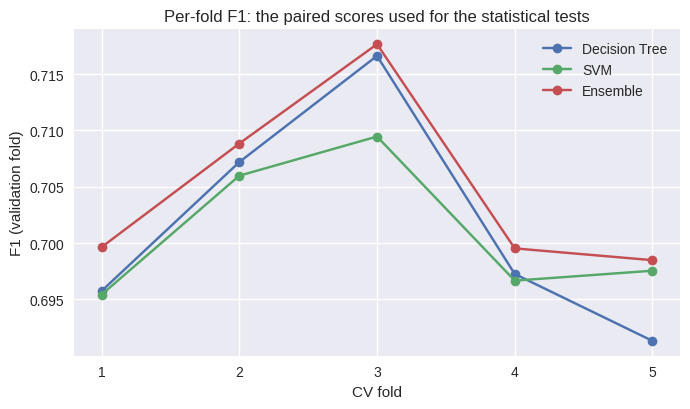

In [ ]:
# 5-fold CV of the three FINAL candidates on the SAME folds
# Decision Tree (best config) | SVM (best config) | Soft-voting ensemble
# Training data only. The test set is not touched.
from joblib import Parallel, delayed

best_dt_name = best_configurations["Decision Tree"]
best_svm_name = best_configurations["SVM"]
MODEL_NAMES = ["Decision Tree", "SVM", "Ensemble"]


def make_rfe_selector():
    """Same RFE settings as the CV pipelines used for hyperparameter selection."""
    return RFE(
        estimator=RandomForestClassifier(
            n_estimators=50, random_state=42, class_weight="balanced", n_jobs=1
        ),
        n_features_to_select=min(BEST_K, X_cv.shape[1]),
        step=3
    )


def build_members():
    """Fresh, unfitted copies of the two selected models."""
    dt = clone(decision_tree_configs[best_dt_name])
    svm = Pipeline([("scaler", StandardScaler()),
                    ("model", clone(svm_configs[best_svm_name]))])
    return dt, svm


def run_fold(fold_id, train_idx, val_idx):
    X_tr, X_va = X_cv.iloc[train_idx], X_cv.iloc[val_idx]
    y_tr, y_va = y_cv.iloc[train_idx], y_cv.iloc[val_idx]

    # feature selection fitted on the training part of the fold only
    selector = make_rfe_selector().fit(X_tr, y_tr)
    chosen = X_tr.columns[selector.support_]
    X_tr, X_va = X_tr[chosen], X_va[chosen]

    dt, svm = build_members()
    dt.fit(X_tr, y_tr)
    svm.fit(X_tr, y_tr)
    ens = SoftVotingEnsemble(dt, svm).fit(X_tr, y_tr, fit_members=False)

    outputs = {
        "Decision Tree": (dt.predict(X_va), dt.predict_proba(X_va)[:, 1]),
        "SVM": (svm.predict(X_va), svm.decision_function(X_va)),
        "Ensemble": (ens.predict(X_va), ens.predict_proba(X_va)[:, 1]),
    }
    rows = []
    for name, (pred, score) in outputs.items():
        row = {"fold": fold_id, "model": name}
        row.update(compute_metrics(y_va, pred, score))
        rows.append(row)
    return rows


FOLD_CACHE = os.path.join(OUTPUT_DIR, "cv_fold_scores.csv")
fold_scores_df = None

# Re-use cached scores only if they were produced with the same selected configurations
if os.path.exists(FOLD_CACHE):
    cached = pd.read_csv(FOLD_CACHE)
    if (set(cached["dt_config"]) == {best_dt_name} and set(cached["svm_config"]) == {best_svm_name}):
        fold_scores_df = cached
        print("Loaded cached per-fold scores (delete the CSV in OUTPUT_DIR to recompute).")

if fold_scores_df is None:
    t0 = time.time()
    print("Running 5-fold CV for Decision Tree, SVM and Ensemble (about 10-15 min on Colab) ...", flush=True)
    fold_rows = Parallel(n_jobs=2)(
        delayed(run_fold)(k, tr, va)
        for k, (tr, va) in enumerate(cv.split(X_cv, y_cv), start=1)
    )
    fold_scores_df = pd.DataFrame([r for rows in fold_rows for r in rows])
    fold_scores_df["dt_config"] = best_dt_name
    fold_scores_df["svm_config"] = best_svm_name
    fold_scores_df.to_csv(FOLD_CACHE, index=False)
    print(f"Done in {(time.time() - t0) / 60:.1f} min")

METRICS = ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "mcc", "kappa"]

# ---- summary: mean +/- SD over the five folds ----
cv_summary = (fold_scores_df.groupby("model")[METRICS].agg(["mean", "std"])
              .loc[MODEL_NAMES])
display(cv_summary.round(4))

# ---- sanity check against the earlier hyperparameter search ----
old = cv_results_df.set_index("Configuration")["Mean CV F1"]
check = pd.DataFrame({
    "Re-computed mean F1": [fold_scores_df.query("model == 'Decision Tree'")["f1"].mean(),
                            fold_scores_df.query("model == 'SVM'")["f1"].mean()],
    "Value in hyperparameter search": [old[best_dt_name], old[best_svm_name]],
}, index=["Decision Tree", "SVM"])
check["abs. difference"] = (check.iloc[:, 0] - check.iloc[:, 1]).abs()
print("Consistency check (should be ~0):")
display(check.round(5))

# ---- per-fold F1 of the three models ----
plt.figure(figsize=(7, 4.2))
for name in MODEL_NAMES:
    s = fold_scores_df[fold_scores_df["model"] == name].sort_values("fold")
    plt.plot(s["fold"], s["f1"], marker="o", label=name)
plt.xticks(range(1, 6))
plt.xlabel("CV fold")
plt.ylabel("F1 (validation fold)")
plt.title("Per-fold F1: the paired scores used for the statistical tests")
plt.legend()
plt.tight_layout()
save_fig("cv_per_fold_f1.png")
plt.show()


## 9. Final testing on the unseen test set

All hyperparameters and the feature subset are now fixed. The three final models are fitted on the **complete training set** and evaluated on the **test set**. The Decision Tree and the SVM are the pipelines already fitted in the cell above ("Refit the selected configurations"). The ensemble is built from those same two fitted models, so the three models are guaranteed to share the same RFE feature subset. **No tuning is done after this point.**


In [ ]:
# Final models (all fitted on the full training set)
dt_pipe = fitted_best_models["Decision Tree"]
svm_pipe = fitted_best_models["SVM"]

selector_final = dt_pipe.named_steps["selector"]
assert (selector_final.support_ == svm_pipe.named_steps["selector"].support_).all(), \
    "DT and SVM pipelines selected different features"

SELECTED_RFE = list(X_cv.columns[selector_final.support_])
print("Final RFE-selected features:", SELECTED_RFE)

X_train_sel = X_cv[SELECTED_RFE]
X_test_sel = X_test_final[SELECTED_RFE]

dt_final = dt_pipe.named_steps["model"]
svm_final = Pipeline([("scaler", svm_pipe.named_steps["scaler"]),
                      ("model", svm_pipe.named_steps["model"])])

# Ensemble = the two fitted members + Platt scaling fitted on the training margins
ensemble_final = SoftVotingEnsemble(dt_final, svm_final).fit(X_train_sel, y_cv, fit_members=False)

# Single evaluation on the test set
test_outputs = {
    "Decision Tree": (dt_final.predict(X_test_sel), dt_final.predict_proba(X_test_sel)[:, 1]),
    "SVM": (svm_final.predict(X_test_sel), svm_final.decision_function(X_test_sel)),
    "Ensemble": (ensemble_final.predict(X_test_sel), ensemble_final.predict_proba(X_test_sel)[:, 1]),
}

# the pre-built pipelines must give identical predictions
assert np.array_equal(dt_pipe.predict(X_test_final), test_outputs["Decision Tree"][0])
assert np.array_equal(svm_pipe.predict(X_test_final), test_outputs["SVM"][0])

final_rows = []
for name, (pred, score) in test_outputs.items():
    m = compute_metrics(y_test_final, pred, score)
    final_rows.append({"Model": name, **m})

final_test_df = pd.DataFrame(final_rows).rename(columns={
    "accuracy": "Accuracy", "precision": "Precision", "recall": "Recall",
    "specificity": "Specificity", "f1": "F1", "roc_auc": "ROC-AUC",
    "mcc": "MCC", "kappa": "Cohen's Kappa"})
final_test_df.to_csv(os.path.join(OUTPUT_DIR, "final_test_results_all_models.csv"), index=False)

display(final_test_df.set_index("Model").style
        .format("{:.4f}").highlight_max(color="lightgreen", axis=0))


Final RFE-selected features: ['weight', 'ap_hi', 'age_years', 'bmi', 'map']


,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,MCC,Cohen's Kappa
Model,,,,,,,,
Decision Tree,0.7086,0.7262,0.6583,0.7577,0.6906,0.7747,0.4183,0.4165
SVM,0.7124,0.7304,0.6623,0.7613,0.6947,0.7603,0.4260,0.4242
Ensemble,0.7136,0.7266,0.6735,0.7526,0.6991,0.7760,0.4277,0.4265


### Test-set plots: confusion matrices, ROC and precision-recall curves

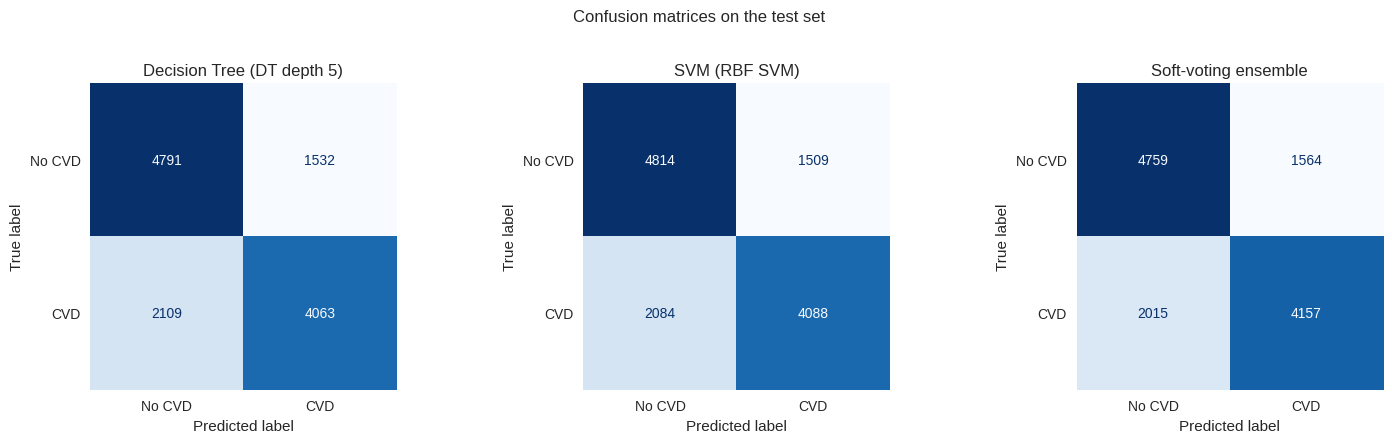

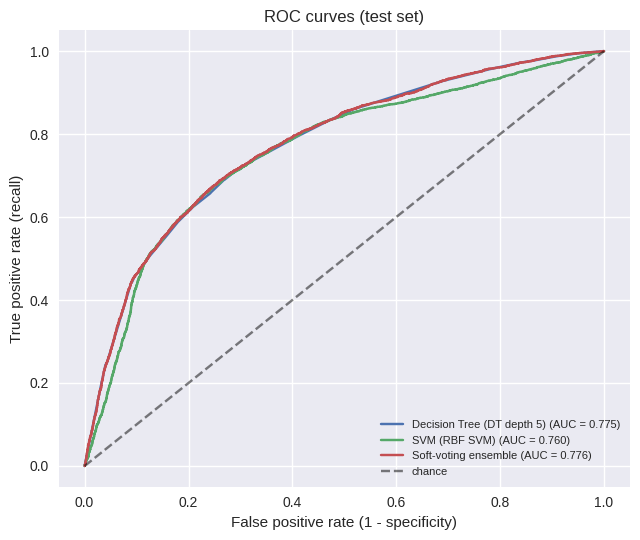

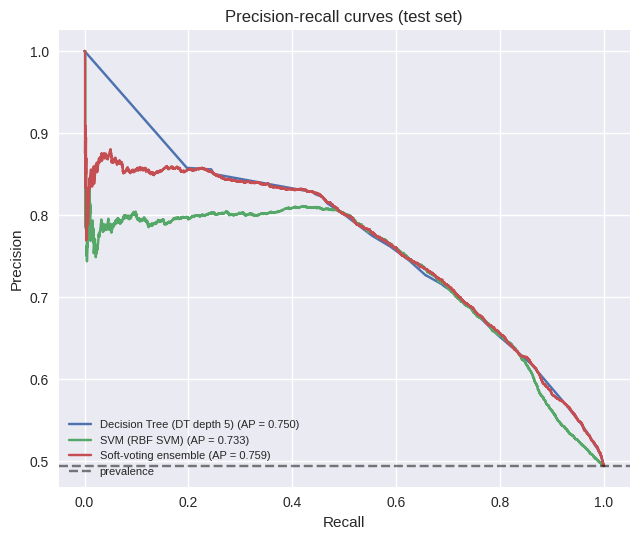

In [ ]:
from sklearn.metrics import (ConfusionMatrixDisplay, precision_recall_curve,
                             average_precision_score)

display_names = {"Decision Tree": f"Decision Tree ({best_dt_name})",
                 "SVM": f"SVM ({best_svm_name})",
                 "Ensemble": "Soft-voting ensemble"}

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (name, (pred, score)) in zip(axes, test_outputs.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_final, pred, display_labels=["No CVD", "CVD"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(display_names[name])
    ax.grid(False)
plt.suptitle("Confusion matrices on the test set", y=1.02)
plt.tight_layout()
save_fig("confusion_matrices.png")
plt.show()

# ROC curves
plt.figure(figsize=(6.5, 5.5))
for name, (pred, score) in test_outputs.items():
    fpr, tpr, _ = roc_curve(y_test_final, score)
    plt.plot(fpr, tpr, label=f"{display_names[name]} (AUC = {roc_auc_score(y_test_final, score):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5, label="chance")
plt.xlabel("False positive rate (1 - specificity)")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves (test set)")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
save_fig("roc_curves.png")
plt.show()

# Precision-recall curves
plt.figure(figsize=(6.5, 5.5))
for name, (pred, score) in test_outputs.items():
    prec, rec, _ = precision_recall_curve(y_test_final, score)
    ap = average_precision_score(y_test_final, score)
    plt.plot(rec, prec, label=f"{display_names[name]} (AP = {ap:.3f})")
plt.axhline(np.mean(y_test_final), color="k", linestyle="--", alpha=0.5, label="prevalence")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curves (test set)")
plt.legend(loc="lower left", fontsize=8)
plt.tight_layout()
save_fig("precision_recall_curves.png")
plt.show()


### Decision Tree: feature importance, tree structure and learning curve

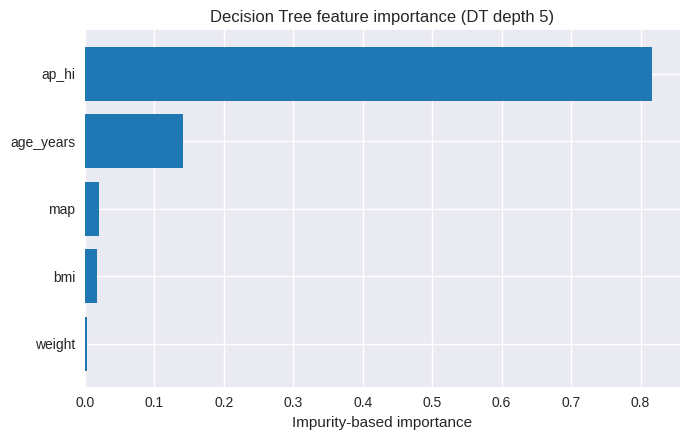

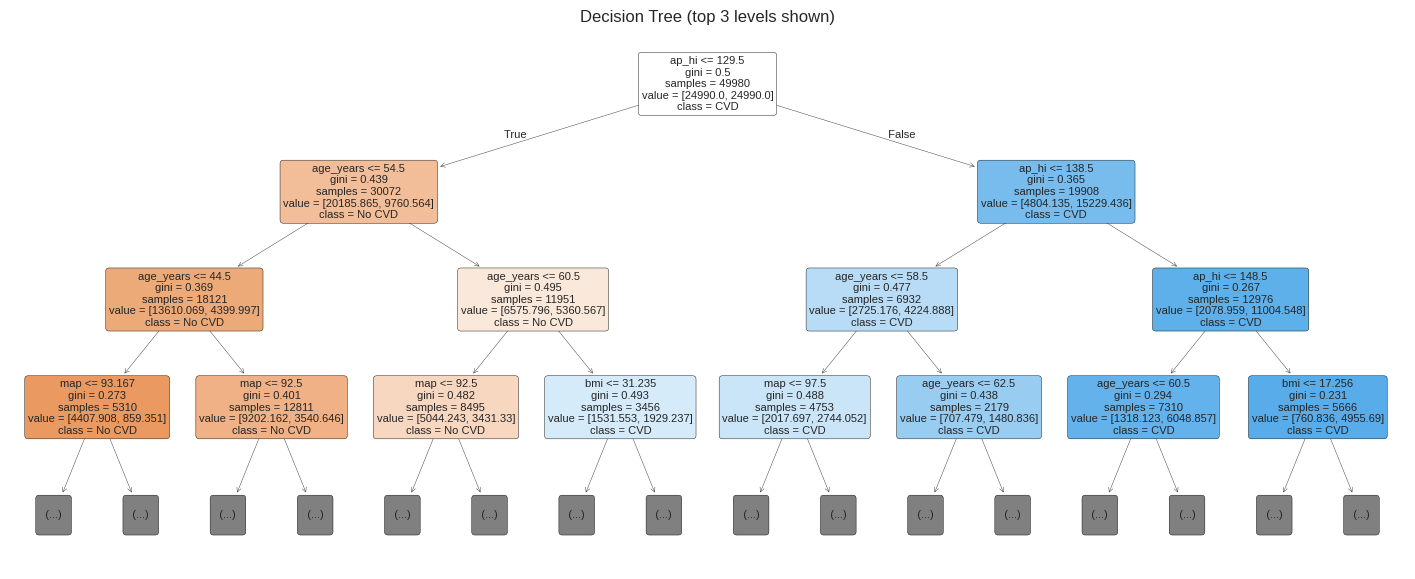

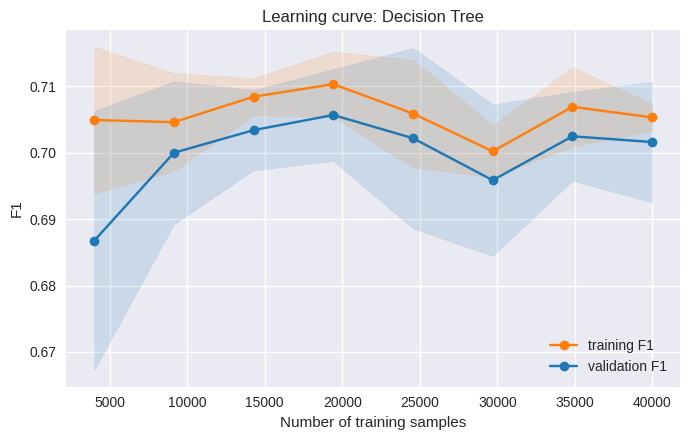

In [ ]:
from sklearn.model_selection import learning_curve

# Feature importance (impurity-based)
imp_dt = pd.Series(dt_final.feature_importances_, index=SELECTED_RFE).sort_values()
plt.figure(figsize=(7, 4.5))
plt.barh(imp_dt.index, imp_dt.values, color="tab:blue")
plt.xlabel("Impurity-based importance")
plt.title(f"Decision Tree feature importance ({best_dt_name})")
plt.tight_layout()
save_fig("dt_feature_importance.png")
plt.show()

# First three levels of the fitted tree
plt.figure(figsize=(18, 7))
plot_tree(dt_final, max_depth=3, feature_names=SELECTED_RFE,
          class_names=["No CVD", "CVD"], filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree (top 3 levels shown)")
save_fig("dt_tree_structure.png")
plt.show()

# Learning curve (optional)
sizes, tr_scores, va_scores = learning_curve(
    clone(dt_final), X_train_sel, y_cv, cv=cv, scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=2, random_state=42, shuffle=True)

plt.figure(figsize=(7, 4.5))
for scores, label, color in [(tr_scores, "training F1", "tab:orange"),
                             (va_scores, "validation F1", "tab:blue")]:
    plt.plot(sizes, scores.mean(axis=1), marker="o", label=label, color=color)
    plt.fill_between(sizes, scores.mean(axis=1) - scores.std(axis=1),
                     scores.mean(axis=1) + scores.std(axis=1), alpha=0.15, color=color)
plt.xlabel("Number of training samples")
plt.ylabel("F1")
plt.title("Learning curve: Decision Tree")
plt.legend()
plt.tight_layout()
save_fig("dt_learning_curve.png")
plt.show()


## 10. Explainable AI with SHAP

SHAP is applied to the **three final models** on the 10 RFE-selected features, in their **original (unscaled) units** so that dependence plots show real values such as mmHg or years. The explained quantity is the **predicted probability of cardiovascular disease**, which makes the three models directly comparable.

| Model | Explainer | Comment |
|---|---|---|
| Decision Tree | `TreeExplainer` (interventional, probability output) | exact |
| SVM (RBF) | `KernelExplainer` | model-agnostic and approximate; the cost grows with the number of support vectors, so a small background set and a sample of test patients are used |
| Soft-voting ensemble | weighted sum of the two sets above | Shapley values are **linear in the model output**. The ensemble probability is 0.5 x DT + 0.5 x calibrated SVM, so its SHAP values are 0.5 x SHAP(DT) + 0.5 x SHAP(SVM), provided both use the same background. An additivity check is printed below. |

The settings `N_BACKGROUND`, `N_EXPLAIN` and `KERNEL_NSAMPLES` control the speed/accuracy trade-off. Expect roughly 5-15 minutes for the SVM explainer on Colab with the defaults. The result is cached in `OUTPUT_DIR`.


In [ ]:
import subprocess, sys
try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

N_BACKGROUND = 20        # background patients used to "remove" features
N_EXPLAIN = 150          # test patients that are explained
KERNEL_NSAMPLES = 300    # coalitions sampled by KernelSHAP (max 2^10 - 2 = 1022 for 10 features)

W_DT, W_SVM = ensemble_final.weights
W_DT, W_SVM = W_DT / (W_DT + W_SVM), W_SVM / (W_DT + W_SVM)

# background: random training patients; explained: stratified random sample of the test set
X_bg = X_train_sel.sample(N_BACKGROUND, random_state=42).astype(float)
y_test_series = pd.Series(y_test_final, index=X_test_sel.index)
X_explain, _, y_explain, _ = train_test_split(
    X_test_sel.astype(float), y_test_series,
    train_size=N_EXPLAIN, stratify=y_test_series, random_state=42)

SVM_LABEL = f"SVM ({best_svm_name})"
DT_LABEL = f"Decision Tree ({best_dt_name})"


# model outputs on raw selected features -> P(CVD)
def f_svm(X):
    X = pd.DataFrame(X, columns=SELECTED_RFE)
    margins = np.asarray(svm_final.decision_function(X)).reshape(-1, 1)
    return ensemble_final.platt_.predict_proba(margins)[:, 1]

def f_ens(X):
    return ensemble_final.predict_proba(pd.DataFrame(X, columns=SELECTED_RFE))[:, 1]

def positive_class(sv):
    """Return SHAP values of class 1 as (n_samples, n_features) for any shap version."""
    if isinstance(sv, list):
        return np.asarray(sv[1])
    sv = np.asarray(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv


# Decision Tree: exact interventional TreeSHAP
expl_dt = shap.TreeExplainer(dt_final, data=X_bg, feature_perturbation="interventional",
                             model_output="probability")
sv_dt = positive_class(expl_dt.shap_values(X_explain, check_additivity=False))
base_dt = float(np.ravel(expl_dt.expected_value)[-1])

# SVM: KernelSHAP (slow part, cached)
SHAP_CACHE = os.path.join(OUTPUT_DIR, f"shap_svm_cache_{N_EXPLAIN}_{N_BACKGROUND}_{KERNEL_NSAMPLES}.npz")
if os.path.exists(SHAP_CACHE):
    cache = np.load(SHAP_CACHE)
    sv_svm, base_svm = cache["sv_svm"], float(cache["base_svm"])
    print("Loaded cached KernelSHAP values for the SVM.")
else:
    t0 = time.time()
    expl_svm = shap.KernelExplainer(f_svm, X_bg.values)
    sv_svm = positive_class(expl_svm.shap_values(X_explain.values, nsamples=KERNEL_NSAMPLES, silent=True))
    base_svm = float(np.ravel(expl_svm.expected_value)[-1])
    np.savez(SHAP_CACHE, sv_svm=sv_svm, base_svm=base_svm)
    print(f"KernelSHAP for the SVM finished in {(time.time() - t0) / 60:.1f} min")

# Ensemble: weighted sum (SHAP is linear in the model output)
sv_ens = W_DT * sv_dt + W_SVM * sv_svm
base_ens = W_DT * base_dt + W_SVM * base_svm

shap_values = {DT_LABEL: sv_dt, SVM_LABEL: sv_svm, "Soft-voting ensemble": sv_ens}
shap_base = {DT_LABEL: base_dt, SVM_LABEL: base_svm, "Soft-voting ensemble": base_ens}

# additivity check: base value + sum of SHAP values = model output
model_out = {DT_LABEL: dt_final.predict_proba(X_explain)[:, 1],
             SVM_LABEL: f_svm(X_explain.values),
             "Soft-voting ensemble": f_ens(X_explain.values)}
print("\nAdditivity check (max |base + sum(SHAP) - model output|):")
for name in shap_values:
    err = np.abs(shap_base[name] + shap_values[name].sum(axis=1) - model_out[name]).max()
    print(f"  {name:35s}: {err:.4f}")


KernelSHAP for the SVM finished in 2.6 min

Additivity check (max |base + sum(SHAP) - model output|):
  Decision Tree (DT depth 5)         : 0.0000
  SVM (RBF SVM)                      : 0.0000
  Soft-voting ensemble               : 0.0000


### Global explanations: SHAP summary (beeswarm) and bar plots

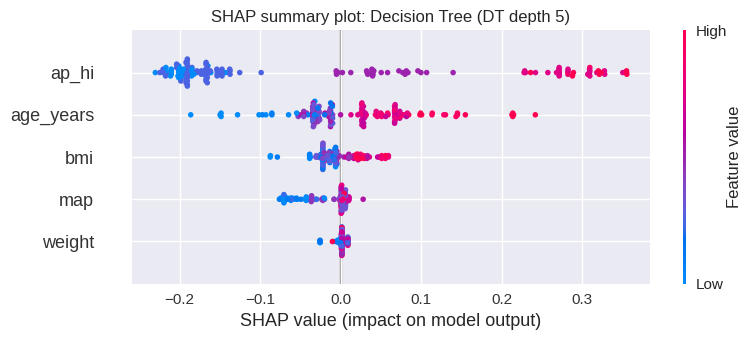

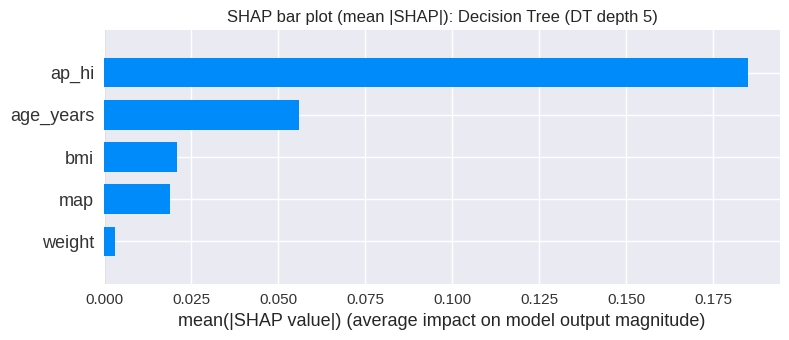

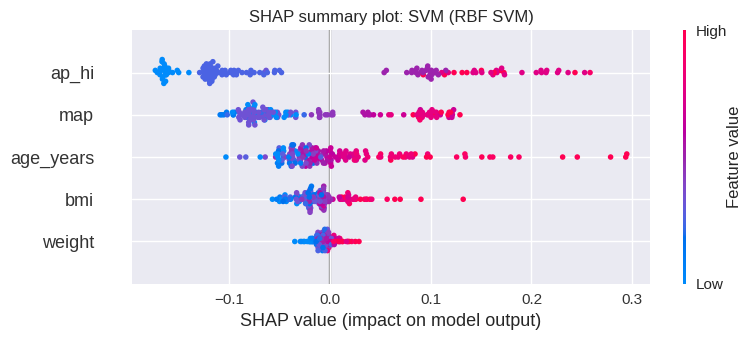

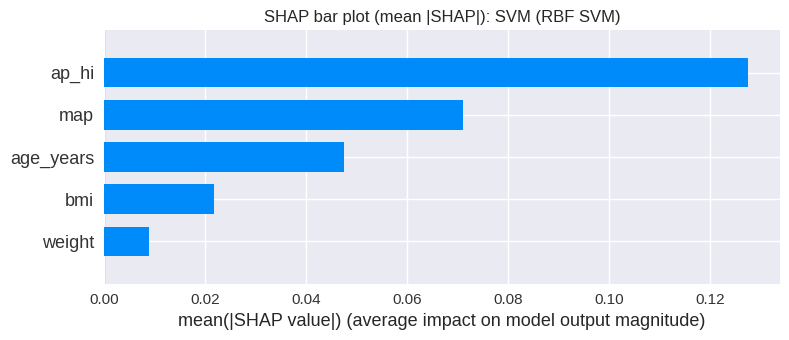

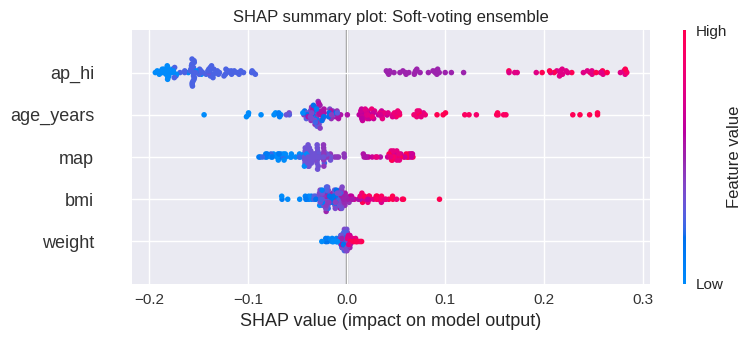

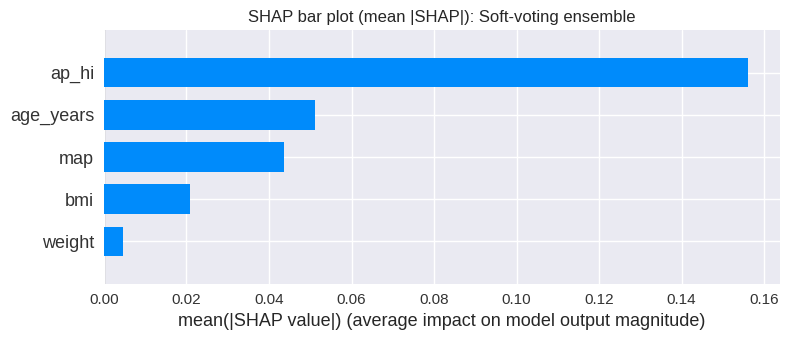

In [ ]:
for name, sv in shap_values.items():
    # summary (beeswarm) plot
    plt.figure()
    shap.summary_plot(sv, X_explain, feature_names=SELECTED_RFE, show=False)
    plt.title(f"SHAP summary plot: {name}")
    plt.tight_layout()
    save_fig("shap_summary_" + name.split(" (")[0].lower().replace(" ", "_").replace("-", "_") + ".png")
    plt.show()

    # bar plot of mean |SHAP|
    plt.figure()
    shap.summary_plot(sv, X_explain, feature_names=SELECTED_RFE, plot_type="bar", show=False)
    plt.title(f"SHAP bar plot (mean |SHAP|): {name}")
    plt.tight_layout()
    save_fig("shap_bar_" + name.split(" (")[0].lower().replace(" ", "_").replace("-", "_") + ".png")
    plt.show()


### SHAP dependence plots (ensemble, top 3 features)

Top-3 features of the ensemble: ['ap_hi', 'age_years', 'map']


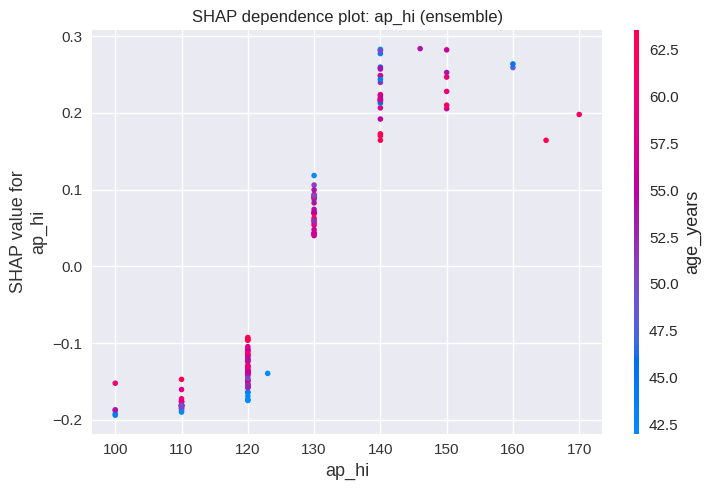

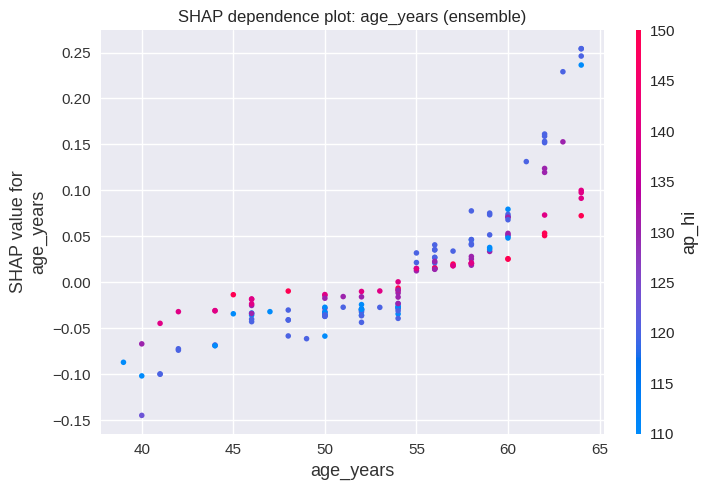

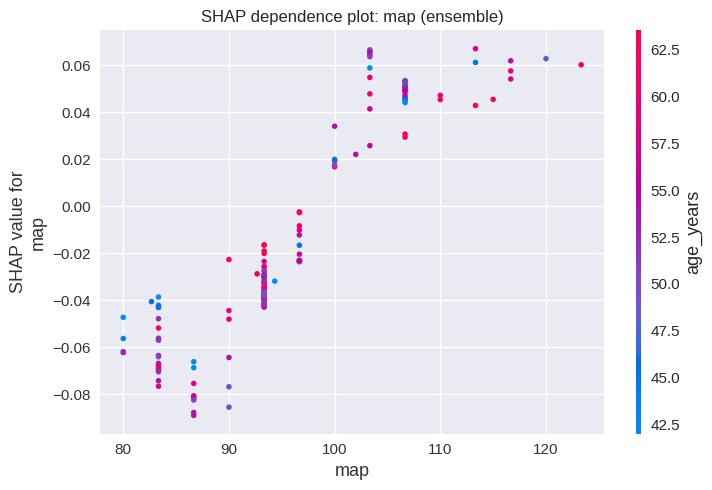

In [ ]:
ens_importance = pd.Series(np.abs(sv_ens).mean(axis=0), index=SELECTED_RFE).sort_values(ascending=False)
top_features = list(ens_importance.index[:3])
print("Top-3 features of the ensemble:", top_features)

for feat in top_features:
    shap.dependence_plot(feat, sv_ens, X_explain, show=False)
    plt.title(f"SHAP dependence plot: {feat} (ensemble)")
    plt.tight_layout()
    save_fig(f"shap_dependence_{feat}.png")
    plt.show()


### Do the models agree on which features matter?

,Decision Tree (DT depth 5),SVM (RBF SVM),Soft-voting ensemble,DT impurity importance,rank: Decision Tree (DT depth 5),rank: SVM (RBF SVM),rank: Soft-voting ensemble,rank: DT impurity importance
ap_hi,65.0,46.0,56.4,81.6,1,1,1,1
age_years,19.7,17.2,18.5,14.2,2,3,2,2
map,6.7,25.7,15.8,2.1,4,2,3,3
bmi,7.4,7.8,7.5,1.8,3,4,4,4
weight,1.1,3.2,1.7,0.3,5,5,5,5


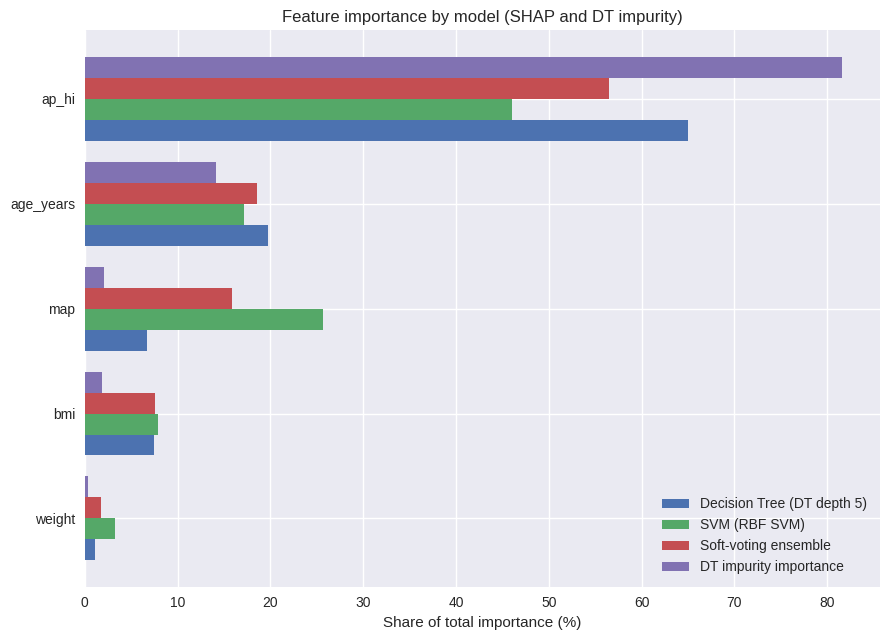

Spearman rank correlation of feature importance between models:


,Decision Tree (DT depth 5),SVM (RBF SVM),Soft-voting ensemble,DT impurity importance
Decision Tree (DT depth 5),1.0,0.7,0.9,0.9
SVM (RBF SVM),0.7,1.0,0.9,0.9
Soft-voting ensemble,0.9,0.9,1.0,1.0
DT impurity importance,0.9,0.9,1.0,1.0


Top-5 (Decision Tree (DT depth 5)): ['ap_hi', 'age_years', 'bmi', 'map', 'weight']
Top-5 (SVM (RBF SVM)): ['ap_hi', 'map', 'age_years', 'bmi', 'weight']
Top-5 (Soft-voting ensemble): ['ap_hi', 'age_years', 'map', 'bmi', 'weight']
Top-5 (DT impurity importance): ['ap_hi', 'age_years', 'map', 'bmi', 'weight']


In [ ]:
imp = pd.DataFrame({name: np.abs(sv).mean(axis=0) for name, sv in shap_values.items()}, index=SELECTED_RFE)
imp_pct = 100 * imp / imp.sum()
imp_pct["DT impurity importance"] = 100 * dt_final.feature_importances_

ranks = imp_pct.rank(ascending=False).astype(int)
comparison = imp_pct.round(1).join(ranks.add_prefix("rank: "))
display(comparison.sort_values("Soft-voting ensemble", ascending=False))

ax = imp_pct.sort_values("Soft-voting ensemble").plot.barh(figsize=(9, 6.5), width=0.8)
ax.set_xlabel("Share of total importance (%)")
ax.set_title("Feature importance by model (SHAP and DT impurity)")
plt.tight_layout()
save_fig("shap_importance_comparison.png")
plt.show()

print("Spearman rank correlation of feature importance between models:")
display(imp_pct.corr(method="spearman").round(2))

for name in imp_pct.columns:
    print(f"Top-5 ({name}): {list(imp_pct[name].sort_values(ascending=False).index[:5])}")


### Local explanations for individual patients

Three patients from the explained test sample are shown for the ensemble: the highest-risk correctly identified patient, the lowest-risk correctly identified patient, and the most confident **misclassification**. Each waterfall plot starts at the base value (average predicted risk of the background patients) and shows how every feature pushes the prediction up (red) or down (blue). The table below each plot shows the SHAP value of each model for the same patient.



High-risk patient (true positive) | true label = 1 | P(CVD): DT = 0.87, SVM = 0.80, ensemble = 0.84


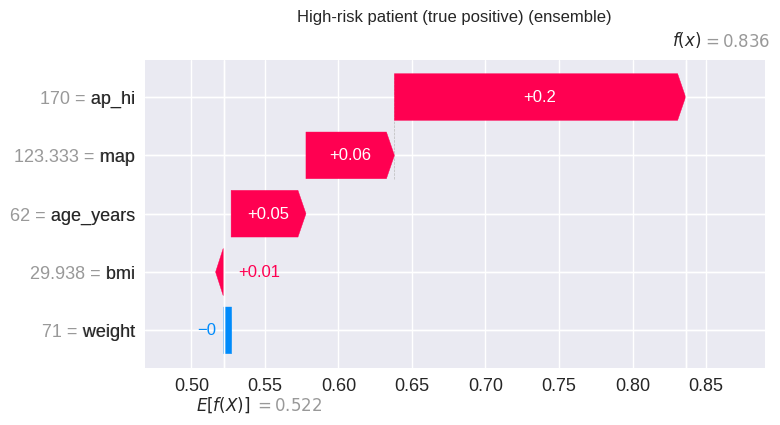

,patient value,SHAP (DT),SHAP (SVM),SHAP (ensemble)
ap_hi,170.000,0.282,0.114,0.198
map,123.333,0.003,0.117,0.060
age_years,62.000,0.051,0.050,0.051
bmi,29.938,0.007,0.003,0.005
weight,71.000,0.001,-0.001,-0.000



Low-risk patient (true negative) | true label = 0 | P(CVD): DT = 0.09, SVM = 0.25, ensemble = 0.17


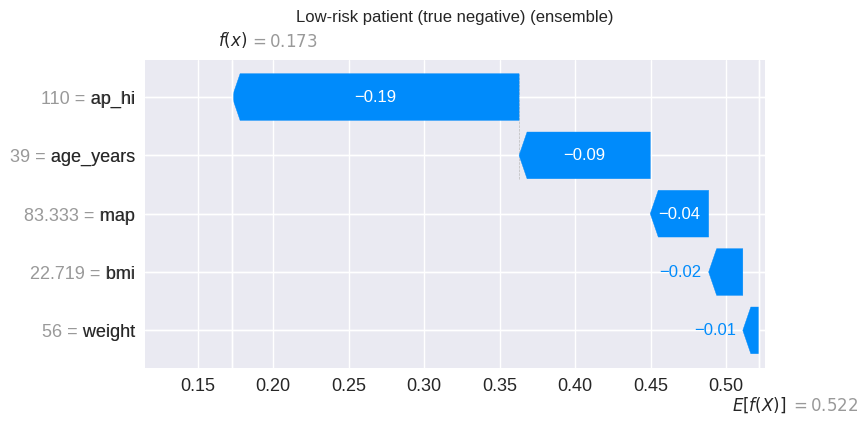

,patient value,SHAP (DT),SHAP (SVM),SHAP (ensemble)
ap_hi,110.000,-0.230,-0.150,-0.190
age_years,39.000,-0.128,-0.046,-0.087
map,83.333,-0.044,-0.033,-0.039
bmi,22.719,-0.024,-0.021,-0.023
weight,56.000,-0.004,-0.018,-0.011



Most confident misclassification | true label = 0 | P(CVD): DT = 0.85, SVM = 0.80, ensemble = 0.82


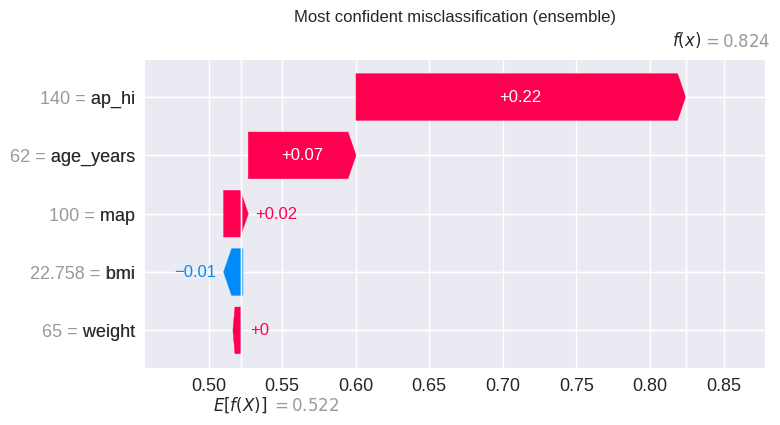

,patient value,SHAP (DT),SHAP (SVM),SHAP (ensemble)
ap_hi,140.000,0.257,0.191,0.224
age_years,62.000,0.074,0.073,0.073
map,100.000,0.001,0.033,0.017
bmi,22.758,-0.007,-0.019,-0.013
weight,65.000,0.001,0.002,0.001


In [ ]:
p_ens = f_ens(X_explain.values)
pred_ens = (p_ens >= 0.5).astype(int)
y_arr = y_explain.values

def pick(mask, key):
    idx = np.where(mask)[0]
    return int(idx[key(idx)]) if len(idx) else None

patients = {
    "High-risk patient (true positive)":  pick((y_arr == 1) & (pred_ens == 1), lambda i: np.argmax(p_ens[i])),
    "Low-risk patient (true negative)":   pick((y_arr == 0) & (pred_ens == 0), lambda i: np.argmin(p_ens[i])),
    "Most confident misclassification":   pick(pred_ens != y_arr, lambda i: np.argmax(np.abs(p_ens[i] - 0.5))),
}

for title, i in patients.items():
    if i is None:
        print(f"{title}: no such patient in the explained sample")
        continue
    print(f"\n{'=' * 70}\n{title} | true label = {y_arr[i]} | "
          f"P(CVD): DT = {model_out[DT_LABEL][i]:.2f}, SVM = {model_out[SVM_LABEL][i]:.2f}, "
          f"ensemble = {p_ens[i]:.2f}")

    shap.plots.waterfall(
        shap.Explanation(values=sv_ens[i], base_values=base_ens,
                         data=X_explain.iloc[i].values, feature_names=SELECTED_RFE),
        max_display=10, show=False)
    plt.title(title + " (ensemble)")
    save_fig("shap_waterfall_" + title.split(" (")[0].lower().replace(" ", "_") + ".png")
    plt.show()

    local = pd.DataFrame({
        "patient value": X_explain.iloc[i].values,
        "SHAP (DT)": sv_dt[i], "SHAP (SVM)": sv_svm[i], "SHAP (ensemble)": sv_ens[i],
    }, index=SELECTED_RFE).sort_values("SHAP (ensemble)", key=abs, ascending=False)
    display(local.round(3))


### Interpreting the SHAP results (complete in the report)

SHAP figures must be **interpreted**, not just shown. Use the plots and tables above to answer, with concrete values:

1. **Global importance.** Which features have the largest mean |SHAP| for each model? Do the Decision Tree, SVM and ensemble rank the same features at the top (see the Spearman table)? If a model relies on different features, suggest why (a tree uses hard thresholds on single features, an RBF-SVM uses smooth distance-based boundaries).
2. **Direction and shape.** In the beeswarm and dependence plots, does higher blood pressure, age or cholesterol raise the predicted risk? Is the effect linear or does it saturate or jump at clinical thresholds (e.g. systolic 140 mmHg)?
3. **Domain knowledge.** Hypertension, age, raised cholesterol and excess body weight are established cardiovascular risk factors. State which of these the models rediscovered and cite your literature sources. Features that matter less than expected (e.g. smoking, alcohol, activity) deserve a comment: they are self-reported, binary and heavily imbalanced in this dataset.
4. **Local explanations.** For each patient above, name the top 2-3 features driving the prediction. For the misclassified patient, explain what pushed the model in the wrong direction and what that says about the limits of the available features.
5. **Caveats.** SHAP explains the *model*, not causality. KernelSHAP is approximate and based on a small background and sample, and the ensemble values rely on the additivity argument stated at the start of this section.


## 11. Statistical analysis: is the ensemble significantly better?

**Procedure (as required).** For each comparison (Decision Tree vs Ensemble, SVM vs Ensemble):

1. Take the five per-fold scores of both models (same folds, so the scores are **paired**) and compute the paired differences *d = score(Ensemble) - score(other model)*.
2. Test the differences for normality with the **Shapiro-Wilk test**.
3. If the differences look normal (p > 0.05) use the **paired t-test**; otherwise use the **Wilcoxon signed-rank test**.

**Hypotheses** (for each comparison): H0: the mean (median) paired difference is 0, i.e. the two models perform equally. H1: the ensemble's score differs from the other model's (two-sided, the primary analysis). Because the brief asks whether the ensemble is *better*, the directional alternative (H1: Ensemble > model, one-sided) is reported as a supplementary result. Significance level: **alpha = 0.05**. The primary metric is **F1**, the criterion used for hyperparameter selection; the other metrics are reported for completeness.

**Limitations to mention in the report.**
* With only **n = 5** folds the tests have very low power. The exact Wilcoxon test cannot produce a two-sided p-value below 2/2^5 = 0.0625 (one-sided: 0.03125), so it can never reach p < 0.05 two-sided with five folds, whatever the data.
* The Shapiro-Wilk test is also weak with n = 5 and "not rejected" is not proof of normality.
* CV folds share training data, so fold scores are not independent and p-values are optimistic (Nadeau & Bengio, 2003).
* The test-set McNemar test at the end of this section is a complementary check with far more data.


In [ ]:
from scipy import stats

ALPHA_STAT = 0.05
PRIMARY_METRIC = "f1"
OTHER_MODELS = ["Decision Tree", "SVM"]

fold_wide = {m: fold_scores_df.pivot(index="fold", columns="model", values=m) for m in METRICS}


def paired_comparison(metric, other, alternative="two-sided", alpha=ALPHA_STAT):
    """Shapiro-Wilk on the paired differences, then paired t-test or Wilcoxon."""
    ens = fold_wide[metric]["Ensemble"].to_numpy()
    oth = fold_wide[metric][other].to_numpy()
    diff = ens - oth                      # positive = ensemble better
    n = len(diff)

    res = {"metric": metric, "comparison": f"{other} vs Ensemble", "alternative": alternative,
           "n_folds": n, "mean_diff": diff.mean(), "sd_diff": diff.std(ddof=1),
           "ens_scores": ens, "other_scores": oth, "diff": diff}

    if np.allclose(diff, 0):
        res.update(shapiro_W=np.nan, shapiro_p=np.nan, normal=False, test="none (identical scores)",
                   statistic=np.nan, p_value=1.0)
        return res

    if np.ptp(diff) < 1e-12:              # constant non-zero difference: Shapiro-Wilk is undefined
        res.update(shapiro_W=np.nan, shapiro_p=np.nan, normal=False)
    else:
        W, p_sh = stats.shapiro(diff)
        res.update(shapiro_W=W, shapiro_p=p_sh, normal=bool(p_sh > alpha))

    if res["normal"]:
        t, p = stats.ttest_rel(ens, oth, alternative=alternative)
        res.update(test="paired t-test", statistic=t, p_value=p)
    else:
        W_stat, p = stats.wilcoxon(diff, alternative=alternative)
        res.update(test="Wilcoxon signed-rank", statistic=W_stat, p_value=p)
    return res


def print_report(r, alpha=ALPHA_STAT):
    sign = {"two-sided": "!=", "greater": ">"}[r["alternative"]]
    print("=" * 78)
    print(f"{r['comparison']}   |   metric: {r['metric'].upper()}   |   alternative: {r['alternative']}")
    print("=" * 78)
    print(f"H0: mean difference (Ensemble - {r['comparison'].split(' vs ')[0]}) = 0   (no difference)")
    print(f"H1: Ensemble {sign} {r['comparison'].split(' vs ')[0]}")
    print(f"Significance level: alpha = {alpha}")
    print(f"Fold scores  {r['comparison'].split(' vs ')[0]:14s}: {np.round(r['other_scores'], 4)}")
    print(f"Fold scores  Ensemble      : {np.round(r['ens_scores'], 4)}")
    print(f"Paired differences         : {np.round(r['diff'], 4)}  (mean = {r['mean_diff']:+.4f}, SD = {r['sd_diff']:.4f})")
    if np.isnan(r["shapiro_p"]):
        print("Shapiro-Wilk               : not applicable (constant differences)")
    else:
        verdict = "normality NOT rejected" if r["normal"] else "normality REJECTED"
        print(f"Shapiro-Wilk               : W = {r['shapiro_W']:.4f}, p = {r['shapiro_p']:.4f} -> {verdict}")
    print(f"Test used                  : {r['test']}")
    stat_name = "t" if r["test"] == "paired t-test" else "W"
    print(f"Test statistic             : {stat_name} = {r['statistic']:.4f}" if not np.isnan(r["statistic"]) else "Test statistic             : n/a")
    print(f"p-value                    : {r['p_value']:.4f}")

    if r["test"].startswith("Wilcoxon"):
        min_p = (2 if r["alternative"] == "two-sided" else 1) / 2 ** r["n_folds"]
        if min_p > alpha:
            print(f"NOTE: with n = {r['n_folds']} the smallest attainable p-value is {min_p:.4f} > alpha, "
                  "so significance is impossible for this test.")

    if r["p_value"] < alpha:
        better = "higher" if r["mean_diff"] > 0 else "lower"
        print(f"Conclusion                 : Reject H0 (p < {alpha}). The ensemble's {r['metric'].upper()} is "
              f"significantly {better} than that of {r['comparison'].split(' vs ')[0]}.")
    else:
        print(f"Conclusion                 : Fail to reject H0 (p >= {alpha}). There is no statistically "
              f"significant difference in {r['metric'].upper()} between the ensemble and "
              f"{r['comparison'].split(' vs ')[0]} at the 5% level.")
    print()


# ---- detailed report for the primary metric ----
primary_results = {}
for other in OTHER_MODELS:
    r = paired_comparison(PRIMARY_METRIC, other, alternative="two-sided")
    primary_results[other] = r
    print_report(r)

# ---- supplementary: directional alternative (Ensemble > model) ----
print("Supplementary one-sided results (H1: Ensemble > model)\n")
for other in OTHER_MODELS:
    print_report(paired_comparison(PRIMARY_METRIC, other, alternative="greater"))


Decision Tree vs Ensemble   |   metric: F1   |   alternative: two-sided
H0: mean difference (Ensemble - Decision Tree) = 0   (no difference)
H1: Ensemble != Decision Tree
Significance level: alpha = 0.05
Fold scores  Decision Tree : [0.6958 0.7072 0.7166 0.6973 0.6913]
Fold scores  Ensemble      : [0.6996 0.7088 0.7177 0.6995 0.6985]
Paired differences         : [0.0039 0.0016 0.001  0.0023 0.0072]  (mean = +0.0032, SD = 0.0025)
Shapiro-Wilk               : W = 0.8817, p = 0.3171 -> normality NOT rejected
Test used                  : paired t-test
Test statistic             : t = 2.9153
p-value                    : 0.0434
Conclusion                 : Reject H0 (p < 0.05). The ensemble's F1 is significantly higher than that of Decision Tree.

SVM vs Ensemble   |   metric: F1   |   alternative: two-sided
H0: mean difference (Ensemble - SVM) = 0   (no difference)
H1: Ensemble != SVM
Significance level: alpha = 0.05
Fold scores  SVM           : [0.6954 0.706  0.7095 0.6967 0.6976]
Fold sco

,Metric,Comparison,Mean diff (Ens - model),Shapiro p,Test,Statistic,p (two-sided),"p (one-sided, Ens > model)","Significant (two-sided, alpha=0.05)","Significant (Bonferroni, alpha=0.025)"
0,ACCURACY,Decision Tree vs Ensemble,+0.0022,0.777,paired t-test,32.865,0.0000,0.0000,True,True
1,ACCURACY,SVM vs Ensemble,-0.0002,0.697,paired t-test,-0.202,0.8500,0.5750,False,False
2,PRECISION,Decision Tree vs Ensemble,+0.0010,0.250,paired t-test,0.537,0.6195,0.3098,False,False
3,PRECISION,SVM vs Ensemble,-0.0069,0.657,paired t-test,-8.545,0.0010,0.9995,True,True
4,RECALL,Decision Tree vs Ensemble,+0.0049,0.334,paired t-test,1.423,0.2277,0.1139,False,False
5,RECALL,SVM vs Ensemble,+0.0128,0.502,paired t-test,6.025,0.0038,0.0019,True,True
6,SPECIFICITY,Decision Tree vs Ensemble,-0.0005,0.298,paired t-test,-0.150,0.8878,0.5561,False,False
7,SPECIFICITY,SVM vs Ensemble,-0.0129,0.388,paired t-test,-10.816,0.0004,0.9998,True,True
8,F1,Decision Tree vs Ensemble,+0.0032,0.317,paired t-test,2.915,0.0434,0.0217,True,False
9,F1,SVM vs Ensemble,+0.0038,0.415,paired t-test,3.141,0.0348,0.0174,True,False


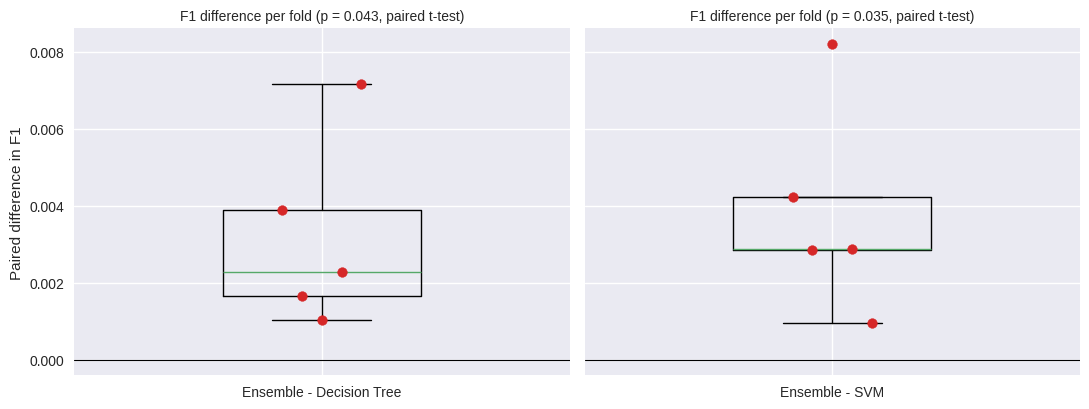

In [ ]:
# ---- summary table: all metrics, both comparisons ----
summary_rows = []
for metric in METRICS:
    for other in OTHER_MODELS:
        two = paired_comparison(metric, other, "two-sided")
        one = paired_comparison(metric, other, "greater")
        summary_rows.append({
            "Metric": metric.upper(),
            "Comparison": two["comparison"],
            "Mean diff (Ens - model)": two["mean_diff"],
            "Shapiro p": two["shapiro_p"],
            "Test": two["test"],
            "Statistic": two["statistic"],
            "p (two-sided)": two["p_value"],
            "p (one-sided, Ens > model)": one["p_value"],
            "Significant (two-sided, alpha=0.05)": two["p_value"] < ALPHA_STAT,
            "Significant (Bonferroni, alpha=0.025)": two["p_value"] < ALPHA_STAT / 2,
        })

stat_summary_df = pd.DataFrame(summary_rows)
stat_summary_df.to_csv(os.path.join(OUTPUT_DIR, "statistical_tests_summary.csv"), index=False)
display(stat_summary_df.style.format({
    "Mean diff (Ens - model)": "{:+.4f}", "Shapiro p": "{:.3f}", "Statistic": "{:.3f}",
    "p (two-sided)": "{:.4f}", "p (one-sided, Ens > model)": "{:.4f}"}))

# ---- paired differences visualised ----
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, other in zip(axes, OTHER_MODELS):
    r = primary_results[other]
    ax.axhline(0, color="k", lw=0.8)
    ax.boxplot(r["diff"], widths=0.4, showfliers=False)
    ax.scatter(np.ones(len(r["diff"])) + np.linspace(-0.08, 0.08, len(r["diff"])), r["diff"],
               color="tab:red", zorder=3, label="fold")
    ax.set_xticks([1]); ax.set_xticklabels([f"Ensemble - {other}"])
    ax.set_title(f"F1 difference per fold (p = {r['p_value']:.3f}, {r['test']})", fontsize=10)
axes[0].set_ylabel("Paired difference in F1")
plt.tight_layout()
save_fig("stat_paired_differences.png")
plt.show()


### Supplementary check: McNemar's test on the test set

In [ ]:
# McNemar's exact test: do the ensemble and a single model make errors on different patients?
# Uses the single final evaluation on the test set (no re-tuning, 12k+ patients -> far more power than 5 folds).
y_true = np.asarray(y_test_final)
pred_ens = test_outputs["Ensemble"][0]

mc_rows = []
for other in OTHER_MODELS:
    pred_oth = test_outputs[other][0]
    ens_right = pred_ens == y_true
    oth_right = pred_oth == y_true
    n_ens_only = int((ens_right & ~oth_right).sum())     # ensemble correct, other wrong
    n_oth_only = int((~ens_right & oth_right).sum())     # other correct, ensemble wrong
    n_disc = n_ens_only + n_oth_only
    p_mc = stats.binomtest(min(n_ens_only, n_oth_only), n_disc, 0.5).pvalue if n_disc > 0 else 1.0
    mc_rows.append({"Comparison": f"{other} vs Ensemble",
                    "Ensemble right, other wrong": n_ens_only,
                    "Other right, ensemble wrong": n_oth_only,
                    "McNemar exact p (two-sided)": p_mc,
                    "Significant (alpha=0.05)": p_mc < ALPHA_STAT})

mcnemar_df = pd.DataFrame(mc_rows)
display(mcnemar_df.style.format({"McNemar exact p (two-sided)": "{:.4f}"}))


,Comparison,"Ensemble right, other wrong","Other right, ensemble wrong",McNemar exact p (two-sided),Significant (alpha=0.05)
0,Decision Tree vs Ensemble,345,283,0.0149,True
1,SVM vs Ensemble,97,83,0.3326,False


## 12. Discussion

The cell below collects the key numbers from the experiments above, so every statement in the discussion is backed by a value from this notebook.


In [ ]:
test_idx = final_test_df.set_index("Model")
best_by_f1 = test_idx["F1"].idxmax()
best_by_auc = test_idx["ROC-AUC"].idxmax()

print("1) BEST MODEL ON THE TEST SET")
print(f"   Highest F1     : {best_by_f1} ({test_idx.loc[best_by_f1, 'F1']:.4f})")
print(f"   Highest ROC-AUC: {best_by_auc} ({test_idx.loc[best_by_auc, 'ROC-AUC']:.4f})")
print(f"   Spread of test F1 across the three models: "
      f"{test_idx['F1'].max() - test_idx['F1'].min():.4f}")

print("\n2) CROSS-VALIDATION (mean F1 +/- SD over 5 folds)")
for name in MODEL_NAMES:
    s = fold_scores_df.query("model == @name")["f1"]
    print(f"   {name:14s}: {s.mean():.4f} +/- {s.std(ddof=1):.4f}")

print("\n3) STATISTICAL TESTS (primary metric F1, two-sided)")
for other, r in primary_results.items():
    verdict = "significant" if r["p_value"] < ALPHA_STAT else "not significant"
    print(f"   {r['comparison']:24s}: {r['test']:22s} p = {r['p_value']:.4f} -> {verdict}")

print("\n4) FEATURE ENGINEERING / SELECTION (CV F1, training data)")
def _f1(set_name, col):
    return fs_results_df.loc[fs_results_df["Feature set"] == set_name, col].iloc[0]
for label, col in [("Decision Tree", "DT F1"), ("SVM (10k subsample)", "SVM F1 (10k subsample)")]:
    print(f"   {label:20s}: original {_f1('Original features', col):.4f} | "
          f"all {_f1('All (original + engineered)', col):.4f} | "
          f"RFE-{BEST_K} {_f1(RFE_LABEL, col):.4f}")

print("\n5) MOST INFLUENTIAL FEATURES (ensemble, mean |SHAP|)")
print("   " + ", ".join(f"{f} ({v:.3f})" for f, v in ens_importance.head(5).items()))


1) BEST MODEL ON THE TEST SET
   Highest F1     : Ensemble (0.6991)
   Highest ROC-AUC: Ensemble (0.7760)
   Spread of test F1 across the three models: 0.0085

2) CROSS-VALIDATION (mean F1 +/- SD over 5 folds)
   Decision Tree : 0.7016 +/- 0.0102
   SVM           : 0.7010 +/- 0.0063
   Ensemble      : 0.7048 +/- 0.0083

3) STATISTICAL TESTS (primary metric F1, two-sided)
   Decision Tree vs Ensemble: paired t-test          p = 0.0434 -> significant
   SVM vs Ensemble         : paired t-test          p = 0.0348 -> significant

4) FEATURE ENGINEERING / SELECTION (CV F1, training data)
   Decision Tree       : original 0.6968 | all 0.6980 | RFE-5 0.7016
   SVM (10k subsample) : original 0.7048 | all 0.6993 | RFE-5 0.7023

5) MOST INFLUENTIAL FEATURES (ensemble, mean |SHAP|)
   ap_hi (0.156), age_years (0.051), map (0.044), bmi (0.021), weight (0.005)


### Discussion guide for the report

Answer each question from the brief using the printed numbers and the figures above:

| Question from the brief | Where the evidence is |
|---|---|
| Which model performed best, and why? | Section 9 test table; Section 8 CV summary. Differences of a few thousandths in F1 are within fold-to-fold noise, so say so. Explain why the winner fits the data (e.g. smooth RBF boundary vs axis-aligned splits, averaging two diverse models). |
| Did feature engineering improve performance? | Feature-set comparison table in the feature-selection section (Original vs All). |
| Did feature selection improve performance? | Same table (All vs ANOVA-selected vs RFE top-k), plus the benefit in model simplicity. |
| Which features were most influential? | DT importance plot, SHAP bar plots and the cross-model comparison table. |
| Did SHAP agree with domain knowledge? | Section 10 interpretation guide. |
| Did the ensemble significantly outperform the individual models? | Section 11 reports, summary table and McNemar test. Report both the p-values and the effect size (mean difference). |
| Limitations? | See below. |
| Future improvements? | See below. |

**Limitations to consider.** (i) Only five CV folds, so the tests have little power; (ii) the dataset is a single-source, mostly self-reported cohort with no lab values or imaging, which limits achievable accuracy (the models here reach about 72-73%); (iii) rows with physiologically impossible blood pressure or body measurements were removed with simple rules, and the IQR outlier filter removed about 9% of the remaining records, which may also have removed genuine extreme patients; (iv) KernelSHAP is approximate; (v) the SVM probabilities were calibrated on the training margins rather than on held-out data.

**Possible improvements.** Nested cross-validation or repeated CV for tests with more power; a wider hyperparameter search (C, gamma, min_samples_leaf); stacking with a learned meta-model instead of equal-weight voting; probability calibration on held-out data; threshold tuning to favour recall in a screening setting; external validation on another cohort.


## 13. Save deliverables

Saves the final cleaned dataset, result tables, figures and fitted models into `OUTPUT_DIR` and zips them so they can be downloaded for the submission (the brief asks for the final cleaned dataset if it was modified).


In [ ]:
import shutil

# final cleaned + engineered dataset
df.to_csv(os.path.join(OUTPUT_DIR, "cardio_cleaned_engineered.csv"), index=False)

# result tables
cv_results_df.to_csv(os.path.join(OUTPUT_DIR, "hyperparameter_cv_results.csv"), index=False)
fold_scores_df.to_csv(os.path.join(OUTPUT_DIR, "cv_fold_scores.csv"), index=False)
final_test_df.to_csv(os.path.join(OUTPUT_DIR, "final_test_results_all_models.csv"), index=False)
fs_results_df.to_csv(os.path.join(OUTPUT_DIR, "feature_set_comparison.csv"), index=False)
selection_table.to_csv(os.path.join(OUTPUT_DIR, "feature_selection_table.csv"), index=False)
comparison.to_csv(os.path.join(OUTPUT_DIR, "shap_importance_comparison.csv"))

# fitted models
with open(os.path.join(OUTPUT_DIR, "final_models.pickle"), "wb") as f:
    pickle.dump({"decision_tree": dt_final, "svm": svm_final, "ensemble": ensemble_final,
                 "selected_features": SELECTED_RFE, "rfe_selector": selector_final}, f)

archive = shutil.make_archive(OUTPUT_DIR.rstrip("/"), "zip", OUTPUT_DIR)
print("Saved files:", sorted(os.listdir(OUTPUT_DIR)))
print("Archive:", archive)

try:                                   # works on Google Colab only
    from google.colab import files
    files.download(archive)
except ImportError:
    pass


Saved files: ['cardio_cleaned_engineered.csv', 'confusion_matrices.png', 'cv_fold_scores.csv', 'cv_per_fold_f1.png', 'dt_feature_importance.png', 'dt_learning_curve.png', 'dt_tree_structure.png', 'feature_selection_table.csv', 'feature_set_comparison.csv', 'final_models.pickle', 'final_test_results.csv', 'final_test_results_all_models.csv', 'hyperparameter_cv_results.csv', 'precision_recall_curves.png', 'roc_curves.png', 'shap_bar_decision_tree.png', 'shap_bar_soft_voting_ensemble.png', 'shap_bar_svm.png', 'shap_dependence_age_years.png', 'shap_dependence_ap_hi.png', 'shap_dependence_map.png', 'shap_importance_comparison.csv', 'shap_importance_comparison.png', 'shap_summary_decision_tree.png', 'shap_summary_soft_voting_ensemble.png', 'shap_summary_svm.png', 'shap_svm_cache_150_20_300.npz', 'shap_waterfall_high-risk_patient.png', 'shap_waterfall_low-risk_patient.png', 'shap_waterfall_most_confident_misclassification.png', 'stat_paired_differences.png', 'statistical_tests_summary.csv', '

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>